# 1. Cadre expérimental consolidé

## 1.1. Objectif expérimental

L'objectif de cette étude est d'évaluer l'intérêt du **Graph Learning**, et plus particulièrement de la modélisation dynamique des interactions transactionnelles, pour la détection de fraude Mobile Money.

L'évaluation ne cherche pas uniquement à déterminer quel modèle obtient la meilleure performance prédictive. Elle vise également à comprendre dans quelles conditions la structure relationnelle et l'historique temporel des transactions apportent réellement une information supplémentaire par rapport à un modèle exploitant principalement les caractéristiques locales de chaque transaction.

Quatre grandes approches sont ainsi comparées :

| Approche | Modèle principal | Information exploitée |
|---|---|---|
| Machine Learning tabulaire | LightGBM Core | Caractéristiques transactionnelles et historiques causales |
| GNN statique | GraphSAGE Core Edge | Caractéristiques de l'arête et voisinage du graphe |
| GNN dynamique | Dynamic GNN TBPTT=2 | Caractéristiques de l'arête et mémoire temporelle des destinations |
| Contrôle neuronal | NoMemory Neural Control | Même base prédictive que le Dynamic GNN, sans mémoire temporelle |

Une variante **LightGBM Full** est également conservée comme expérience complémentaire afin d'étudier l'effet de variables fortement liées au mécanisme de simulation de PaySim.

Enfin, une expérience ciblée avec **TBPTT=16** a été conduite pour vérifier si une propagation plus longue du gradient temporel améliorait l'apprentissage de la mémoire dynamique.

## 1.2. Dataset et déséquilibre de classes

Les expérimentations reposent sur le dataset simulé **PaySim**, composé de :

| Propriété | Valeur |
|---|---:|
| Nombre total de transactions | 6 362 620 |
| Nombre de transactions frauduleuses | 8 213 |
| Taux global de fraude | $\approx 0,1291\%$ |
| Nombre de steps temporels | 743 |
| Premier step | 1 |
| Dernier step | 743 |

Les transactions appartiennent à cinq catégories :

`CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT` et `TRANSFER`.

La fraude constitue donc un événement extrêmement minoritaire. Dans ce contexte, l'accuracy est peu informative et la **PR-AUC** constitue la métrique principale de comparaison des modèles.

La ROC-AUC, la précision, le rappel et le score F1 sont néanmoins conservés comme métriques complémentaires afin de caractériser plus précisément le comportement des différents systèmes.

## 1.3. Découpage temporel

Afin de reproduire un scénario réaliste dans lequel un modèle est entraîné sur le passé puis appliqué à des transactions futures, les données ont été divisées exclusivement selon leur ordre temporel.

| Split | Steps | Transactions | Fraudes |
|---|---|---:|---:|
| Train | 1–334 | 4 771 387 | 3 745 |
| Validation | 335–392 | 792 406 | 638 |
| Test | 393–743 | 798 827 | 3 830 |

Aucune stratification ni redistribution aléatoire des observations n'a été réalisée.

Une différence importante de prévalence de fraude existe entre les périodes de validation et de test. Le taux de fraude du Test est environ **5,95 fois supérieur** à celui de la Validation.

Cette évolution doit être prise en compte lors de l'interprétation des résultats, notamment pour la PR-AUC, dont la valeur dépend de la prévalence de la classe positive.

Les performances obtenues sur Validation et Test ne doivent donc pas être interprétées comme deux mesures directement interchangeables d'une distribution identique. L'intérêt principal du Test reste l'évaluation finale sur une période future totalement exclue du processus de sélection.

## 1.4. Protocole de sélection et prévention des fuites

L'ensemble de la chaîne expérimentale suit un protocole temporel strict.

Le Train est utilisé pour l'apprentissage des paramètres des modèles.

La Validation est utilisée pour :

- comparer les variantes ;
- sélectionner les architectures ;
- choisir les hyperparamètres ;
- sélectionner les seuils de décision.

Le Test est réservé exclusivement à l'évaluation finale des modèles préalablement sélectionnés.

En particulier :

- aucun modèle n'est sélectionné à partir de ses performances sur Test ;
- aucun seuil n'est optimisé sur Test ;
- aucun hyperparamètre n'est choisi après observation des résultats Test ;
- aucune transaction future n'est utilisée pour construire les variables d'une transaction passée ;
- aucun mélange aléatoire entre périodes temporelles n'est effectué.

Ce protocole permet de limiter les risques de fuite temporelle et de produire une évaluation plus proche d'un système de détection de fraude utilisé en conditions opérationnelles.

## 1.5. Causalité du graphe dynamique

Pour les modèles exploitant une représentation temporelle du graphe, la prédiction respecte une causalité stricte.

Pour un step temporel $t$, le système suit la séquence :

$$
State_{<t}
\rightarrow
Prediction(E_t)
\rightarrow
Update(E_t)
$$

où $State_{<t}$ représente l'état construit uniquement à partir des événements antérieurs au step $t$, et $E_t$ l'ensemble des transactions observées au step courant.

Les événements appartenant à $E_t$ ne peuvent donc pas être utilisés pour prédire les autres événements du même step.

Cette règle garantit qu'aucune information contemporaine ou future n'est introduite artificiellement dans la représentation utilisée au moment de la prédiction.

## 1.6. Logique générale de comparaison

La comparaison expérimentale a été construite de manière à isoler progressivement la contribution des différentes sources d'information.

**LightGBM Core** représente la référence tabulaire principale et permet de mesurer la force du signal contenu directement dans les caractéristiques transactionnelles et historiques causales.

**GraphSAGE Core Edge** teste l'apport d'un message passing spatial sur le graphe transactionnel.

Le **Dynamic GNN** ajoute une mémoire temporelle destination-centric destinée à exploiter l'historique des comptes récurrents.

Le **NoMemory Neural Control** conserve une base prédictive neuronale comparable au Dynamic GNN, mais supprime la mémoire, la GRU et les informations temporelles associées. Il constitue ainsi une ablation essentielle pour mesurer directement la valeur ajoutée de la mémoire dynamique.

Enfin, l'expérience **TBPTT=16** vérifie si les résultats du modèle dynamique peuvent être expliqués par une propagation temporelle du gradient trop courte lors de l'entraînement initial.

Cette organisation permet de distinguer trois questions différentes :

1. le graphe spatial améliore-t-il la détection par rapport aux caractéristiques transactionnelles seules ?
2. une mémoire temporelle apporte-t-elle un gain par rapport au même prédicteur sans mémoire ?
3. les éventuelles limites de la mémoire proviennent-elles simplement d'un horizon de gradient insuffisant ?

La comparaison finale des modèles doit être interprétée à partir de ces trois questions plutôt que comme un simple classement de scores.

# 2. Comparaison globale des modèles

## 2.1. Objectif de la comparaison

La comparaison globale vise à mesurer la contribution successive de trois types d'information :

1. les caractéristiques transactionnelles locales ;
2. la structure relationnelle du graphe ;
3. la mémoire temporelle des interactions passées.

La **PR-AUC** est retenue comme métrique principale en raison du fort déséquilibre entre transactions normales et frauduleuses.

Les autres métriques sont conservées afin de caractériser le comportement des modèles au seuil de décision sélectionné exclusivement sur l'ensemble de Validation.

## 2.2. Résultats finaux sur le Test

| Modèle | PR-AUC | ROC-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| GraphSAGE Core Edge | 0.352779 | 0.959934 | 0.927941 | 0.164752 | 0.279823 |
| Dynamic GNN TBPTT=2 | 0.689456 | 0.978403 | 0.945424 | 0.434204 | 0.595098 |
| NoMemory Neural Control | 0.749854 | 0.987748 | 0.937348 | 0.503916 | 0.655459 |
| **LightGBM Core** | **0.979749** | **0.999890** | **0.982230** | **0.793730** | **0.877980** |

La hiérarchie finale selon la PR-AUC est donc :

$$
\text{GraphSAGE}
<
\text{Dynamic GNN}
<
\text{NoMemory Control}
<
\text{LightGBM Core}
$$

## 2.3. Écarts entre modèles

La comparaison des PR-AUC permet de quantifier les différences de performance.

| Comparaison | Écart absolu de PR-AUC |
|---|---:|
| Dynamic GNN − GraphSAGE | +0.336677 |
| NoMemory − Dynamic GNN | +0.060398 |
| LightGBM Core − NoMemory | +0.229895 |
| LightGBM Core − GraphSAGE | +0.626970 |

Le passage de GraphSAGE au modèle dynamique produit donc une amélioration importante :

$$
0.689456 - 0.352779 = 0.336677
$$

Cette progression montre qu'une architecture prenant explicitement en compte la temporalité est nettement plus adaptée que le message passing spatial statique dans ce contexte.

Cependant, ce résultat ne suffit pas à démontrer l'utilité de la mémoire temporelle.

Lorsque cette mémoire est supprimée tout en conservant un prédicteur neuronal comparable, la PR-AUC augmente encore :

$$
0.749854 - 0.689456 = 0.060398
$$

Le contrôle sans mémoire dépasse donc le Dynamic GNN.

Enfin, LightGBM Core reste largement supérieur aux approches neuronales étudiées :

$$
0.979749 - 0.749854 = 0.229895
$$

par rapport au meilleur modèle neuronal évalué.

## 2.4. Résultat central de l'ablation dynamique

L'un des résultats les plus importants du projet provient de la comparaison entre le Dynamic GNN et son contrôle sans mémoire.

Sur Validation :

$$
\Delta_{\text{Dynamic-Control}}
=
-0.059197
$$

Sur Test :

$$
\Delta_{\text{Dynamic-Control}}
=
-0.060397
$$

Les deux écarts sont presque identiques.

Cette stabilité est particulièrement importante car elle indique que la sous-performance du modèle dynamique n'est pas uniquement un accident observé sur la période de Test.

Elle apparaît déjà sur Validation, qui est la période utilisée pour la sélection expérimentale, puis se reproduit avec pratiquement la même amplitude sur une période future indépendante.

Le résultat soutient donc de manière assez robuste l'observation suivante :

> Dans le setting étudié sur PaySim, l'ajout de la mémoire temporelle destination-centric n'améliore pas les performances du prédicteur neuronal correspondant.

Cette conclusion reste volontairement limitée à l'architecture et au dataset étudiés.

## 2.5. Lecture Precision–Recall

Les différences entre les modèles apparaissent également clairement dans leur capacité à retrouver les fraudes.

Le GraphSAGE atteint une précision élevée :

$$
Precision = 0.927941
$$

mais un rappel très faible :

$$
Recall = 0.164752
$$

Il identifie donc relativement peu de transactions comme frauduleuses, mais ses alertes positives sont généralement correctes.

Le Dynamic GNN améliore fortement le rappel :

$$
Recall = 0.434204
$$

tandis que le contrôle sans mémoire atteint :

$$
Recall = 0.503916
$$

Le gain du contrôle par rapport au modèle dynamique ne correspond donc pas seulement à une amélioration abstraite de la PR-AUC : il se traduit également par une plus grande proportion de fraudes effectivement détectées.

LightGBM Core reste nettement devant avec :

$$
Recall = 0.793730
$$

tout en maintenant une précision très élevée :

$$
Precision = 0.982230
$$

Il présente ainsi le meilleur compromis opérationnel parmi les modèles Core étudiés.

## 2.6. Pourquoi la ROC-AUC ne suffit pas

Tous les modèles présentent des ROC-AUC relativement élevées, y compris GraphSAGE :

$$
ROC\text{-}AUC_{\text{GraphSAGE}} = 0.959934
$$

alors que sa PR-AUC n'est que :

$$
PR\text{-}AUC_{\text{GraphSAGE}} = 0.352779
$$

Cette différence illustre les limites de la ROC-AUC dans un problème où la classe frauduleuse est extrêmement minoritaire.

Un modèle peut conserver une excellente capacité globale à classer les transactions normales sans pour autant être suffisamment performant sur la classe positive.

La PR-AUC fournit donc ici une lecture plus discriminante de la qualité réelle de détection des fraudes.

## 2.7. Position particulière de LightGBM Full

LightGBM Full obtient les performances les plus élevées de toutes les expériences :

| Modèle | Validation PR-AUC | Test PR-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| LightGBM Full | 1.000000 | 0.999740 | 0.999738 | 0.997389 | 0.998562 |

Ces performances sont presque parfaites.

Cependant, environ **99,79 % du gain d'importance du modèle est associé aux variables PaySim-sensitive**, avec notamment :

$$
amount\_equals\_oldbalance \approx 99.66\%
$$

du gain d'importance.

Ces variables exploitent des régularités particulièrement liées au mécanisme de génération du dataset simulé PaySim.

Pour cette raison, LightGBM Full ne doit pas être considéré comme la référence scientifique principale du projet malgré ses performances supérieures.

La référence retenue pour les comparaisons principales reste donc :

$$
\boxed{\text{LightGBM Core}}
$$

Ce choix privilégie une interprétation plus réaliste et plus transférable des résultats plutôt que la recherche du score maximal sur PaySim.

## 2.8. Premier enseignement global

La comparaison finale met en évidence trois résultats majeurs.

Premièrement, l'introduction d'une modélisation temporelle améliore fortement les performances par rapport au GraphSAGE statique.

Deuxièmement, cette amélioration ne provient pas nécessairement de la mémoire temporelle elle-même, puisque le contrôle neuronal sans mémoire dépasse le Dynamic GNN.

Troisièmement, les caractéristiques transactionnelles exploitées par LightGBM Core contiennent un signal prédictif beaucoup plus fort que celui extrait des relations du graphe par les architectures GNN étudiées.

Le classement obtenu ne signifie donc pas simplement que LightGBM est un meilleur algorithme.

Il suggère surtout que, dans PaySim, **la nature de l'information disponible favorise fortement les caractéristiques transactionnelles locales par rapport à la structure relationnelle du graphe**.

Cette hypothèse doit maintenant être confrontée aux propriétés structurelles du graphe PaySim.

# 3. LightGBM Core vs LightGBM Full

## 3.1. Objectif de la comparaison

Deux variantes principales de LightGBM ont été évaluées :

- **LightGBM Core**, construit à partir d'un ensemble de variables considérées comme plus défendables pour une détection de fraude réaliste ;
- **LightGBM Full**, qui ajoute des variables fortement liées aux mécanismes internes de génération du dataset PaySim.

L'objectif de cette comparaison n'est donc pas uniquement de déterminer quelle variante obtient le meilleur score, mais d'évaluer dans quelle mesure cette amélioration repose sur des informations susceptibles de se généraliser au-delà du dataset simulé.

## 3.2. Performances observées

Les deux modèles présentent des performances très élevées, mais LightGBM Full atteint des résultats presque parfaits.

| Modèle | Validation PR-AUC | Test PR-AUC | Precision Test | Recall Test | F1 Test |
|---|---:|---:|---:|---:|---:|
| **LightGBM Core** | 0.929704 | 0.979749 | 0.982230 | 0.793730 | 0.877980 |
| **LightGBM Full** | 1.000000 | 0.999740 | 0.999738 | 0.997389 | 0.998562 |

L'écart de PR-AUC sur Test est :

$$
0.999740 - 0.979749 = 0.019991
$$

La différence absolue de PR-AUC peut sembler relativement faible compte tenu du niveau déjà très élevé de LightGBM Core.

En revanche, l'amélioration du rappel est importante :

$$
0.997389 - 0.793730 = 0.203659
$$

LightGBM Full détecte donc presque toutes les fraudes du Test, tout en maintenant une précision proche de 100 %.

Pris isolément, ce résultat pourrait conduire à retenir immédiatement LightGBM Full comme meilleur modèle du projet.

Cette conclusion serait néanmoins incomplète.

## 3.3. Origine du gain de LightGBM Full

L'analyse de l'importance des variables montre que les performances de LightGBM Full reposent presque entièrement sur les variables qualifiées de **PaySim-sensitive**.

Environ :

$$
99.79\%
$$

du gain d'importance du modèle provient de ces variables.

Une seule variable, `amount_equals_oldbalance`, représente environ :

$$
99.66\%
$$

du gain total.

Cette concentration extrême signifie que le modèle ne bénéficie pas simplement d'une combinaison plus riche d'informations transactionnelles.

Il exploite principalement une régularité très spécifique du dataset.

## 3.4. Pourquoi ces variables sont problématiques pour l'interprétation scientifique

PaySim est un simulateur de transactions financières.

Certaines variables peuvent donc refléter directement ou indirectement les règles utilisées pour générer les comportements frauduleux.

Une variable telle que :

`amount_equals_oldbalance`

décrit une situation où le montant de la transaction correspond exactement au solde disponible avant l'opération.

Si cette configuration est fortement associée aux fraudes en raison du mécanisme de simulation de PaySim, un modèle peut obtenir des performances exceptionnelles en apprenant cette règle sans nécessairement découvrir un comportement frauduleux généralisable à de véritables réseaux Mobile Money.

Il ne s'agit pas nécessairement d'une fuite de données au sens temporel ou méthodologique.

La variable est disponible au moment de la transaction et le protocole Train/Validation/Test reste correctement respecté.

Le problème est différent : il concerne la **validité externe** du signal appris.

Autrement dit, la question n'est pas :

> Le modèle triche-t-il avec le Test ?

La réponse est non.

La véritable question est :

> Le signal exploité correspond-il à une propriété suffisamment réaliste pour soutenir une conclusion générale sur la détection de fraude Mobile Money ?

Sur ce point, une interprétation prudente est nécessaire.

## 3.5. Différence entre fuite de données et biais de simulation

Il est important de distinguer clairement deux concepts.

### Fuite de données

Une fuite apparaîtrait, par exemple, si :

- une information future était utilisée pour prédire le passé ;
- le label était directement ou indirectement inclus dans les variables ;
- le Test intervenait dans l'entraînement ou la sélection des hyperparamètres.

Ces situations ont été explicitement évitées dans le protocole expérimental.

### Biais lié au simulateur

Le biais observé ici est différent.

Une variable peut être parfaitement causale et correctement calculée, tout en étant anormalement prédictive parce que le simulateur applique une règle déterministe ou presque déterministe lors de la génération des fraudes.

Dans ce cas, le score mesuré sur PaySim reste valide pour PaySim, mais sa transférabilité vers des données réelles devient incertaine.

C'est précisément la situation qui motive la distinction entre les ensembles de variables **Core** et **Full**.

## 3.6. Pourquoi LightGBM Core reste la référence principale

LightGBM Core atteint déjà :

$$
PR\text{-}AUC = 0.979749
$$

sur le Test, sans dépendre du même ensemble de variables fortement sensibles aux mécanismes de simulation.

Il constitue donc un compromis plus pertinent entre :

- performance prédictive ;
- interprétabilité ;
- réalisme des variables ;
- transférabilité potentielle ;
- comparabilité avec les modèles graphes.

Le choix de LightGBM Core comme référence principale n'est donc pas motivé par une volonté d'ignorer le meilleur modèle.

Il résulte d'un choix méthodologique :

> privilégier le modèle dont les performances semblent reposer sur un signal plus défendable scientifiquement.

LightGBM Full reste néanmoins important dans l'étude.

Il démontre qu'une exploitation agressive de certaines particularités de PaySim permet d'obtenir une détection presque parfaite.

Ce résultat constitue en lui-même un enseignement sur les limites du benchmark.

## 3.7. Ce que LightGBM Full révèle sur PaySim

Les performances de LightGBM Full montrent que PaySim contient des régularités locales extrêmement fortes.

Cela a deux conséquences importantes.

Premièrement, le dataset peut favoriser des modèles tabulaires capables d'exploiter directement ces régularités.

Deuxièmement, il devient difficile pour une architecture de Graph Learning d'apporter un gain supplémentaire lorsque la transaction elle-même contient déjà presque toute l'information nécessaire à la classification.

Cette observation fournit une première explication possible de l'écart important entre LightGBM et les modèles GNN étudiés.

Le problème n'est donc pas uniquement que les GNN aient du mal à apprendre le graphe.

Il est également possible que la **valeur marginale du graphe soit faible**, car le signal transactionnel local est déjà extrêmement discriminant.

## 3.8. Positionnement final des deux modèles

Les deux modèles doivent être conservés dans le mémoire, mais avec des rôles différents.

**LightGBM Core** constitue :

- la référence tabulaire principale ;
- le meilleur modèle scientifique de comparaison ;
- la baseline forte utilisée pour évaluer l'intérêt du Graph Learning.

**LightGBM Full** constitue :

- une expérience complémentaire ;
- une estimation de la performance maximale obtenue avec les variables disponibles ;
- une démonstration de la sensibilité de PaySim à certaines variables issues de son mécanisme de simulation.

La conclusion à retenir est donc :

> LightGBM Full obtient les meilleures performances numériques, mais celles-ci reposent presque entièrement sur des variables fortement spécifiques à PaySim. Pour cette raison, LightGBM Core est retenu comme référence scientifique principale, car il fournit une comparaison plus prudente et plus défendable vis-à-vis des modèles de Graph Learning.

# 4. Structure du graphe PaySim et impact sur l’apprentissage

## 4.1. Objectif de l’analyse

L’intérêt d’un modèle de Graph Learning dépend directement de la structure du graphe sur lequel il est appliqué.

Dans un problème de fraude transactionnelle, un GNN peut théoriquement exploiter :

- les relations répétées entre comptes ;
- les voisinages partagés ;
- les motifs locaux ;
- la récurrence des interactions ;
- les chemins transactionnels ;
- les comportements collectifs ;
- l’historique relationnel des nœuds.

L’analyse structurelle de PaySim permet donc de vérifier si ces sources d’information sont effectivement présentes en quantité suffisante.

## 4.2. Taille et définition du graphe

Le graphe transactionnel contient :

| Propriété | Valeur |
|---|---:|
| Nombre de nœuds | 9 073 900 |
| Nombre d’arêtes | 6 362 620 |
| Couples dirigés uniques | 6 362 620 |
| Self-loops | 0 |
| Arêtes réciproques | 0 |
| Cycles | 0 |

Chaque transaction est représentée par une arête dirigée :

$$
source \rightarrow destination
$$

La tâche est formulée comme un problème de **classification d’arêtes**.

Un premier résultat particulièrement important est que le nombre de couples dirigés uniques est exactement égal au nombre total d’arêtes.

Autrement dit, aucune paire source-destination ne se répète dans le dataset.

Cette propriété limite fortement l’apprentissage de motifs relationnels récurrents entre deux comptes.

## 4.3. Faible densité du graphe

Le graphe est extrêmement sparse.

Environ :

$$
94.83\%
$$

des nœuds possèdent un degré total égal à 1.

Et environ :

$$
95.78\%
$$

des nœuds ont un degré total inférieur ou égal à 2.

La grande majorité des comptes sont donc reliés à très peu d’autres comptes.

Le degré sortant est lui aussi très limité :

- médiane : 1 ;
- 99 % des sources ont un out-degree égal à 1 ;
- maximum observé : 3.

Cette structure est très différente de celle de réseaux transactionnels réels fortement récurrents, où certains comptes peuvent interagir régulièrement avec de nombreux autres acteurs.

## 4.4. Structure des composantes

Le graphe contient environ :

$$
2\,711\,280
$$

composantes faiblement connexes.

La plus grande composante ne contient que :

$$
121
$$

nœuds.

Les composantes sont essentiellement constituées de :

- paires ;
- étoiles ;
- petits arbres.

Environ :

$$
83.17\%
$$

des composantes correspondent à des paires.

Environ :

$$
16.50\%
$$

correspondent à des structures en étoile.

Les autres structures ne représentent qu’une faible fraction du graphe.

De plus, le graphe ne contient aucun cycle.

Il s’agit donc d’un ensemble de structures locales très fragmentées plutôt que d’un grand réseau transactionnel fortement connecté.

## 4.5. Asymétrie entre rôles source et destination

La séparation entre sources et destinations est également très marquée.

| Rôle | Nombre de comptes |
|---|---:|
| Sources uniquement | 6 351 538 |
| Destinations uniquement | 2 720 593 |
| Comptes jouant les deux rôles | 1 769 |

Seulement :

$$
1\,769
$$

comptes apparaissent à la fois comme source et comme destination.

Cela représente environ :

$$
0.0195\%
$$

des nœuds du graphe.

Cette quasi-absence de chevauchement entre les rôles réduit fortement la possibilité de propager une information riche à travers plusieurs étapes relationnelles.

Un compte source observe très rarement un historique dans lequel il aurait précédemment reçu des transactions.

De manière symétrique, la majorité des destinations ne deviennent jamais à leur tour des sources.

Le graphe ressemble donc davantage à un ensemble de flux dirigés vers des destinations qu’à un réseau social ou financier fortement interactif.

## 4.6. Faible profondeur relationnelle

La profondeur utile du graphe reste limitée.

Environ :

$$
35.44\%
$$

des nœuds sont couverts à un hop.

Environ :

$$
61.03\%
$$

sont couverts à deux hops ou moins.

Seulement :

$$
3.53\%
$$

nécessitent une profondeur supérieure à deux hops.

Cette faible profondeur limite l’intérêt d’un message passing profond.

L’ajout de couches GNN supplémentaires augmente alors la complexité du modèle sans nécessairement apporter une quantité significative d’information relationnelle supplémentaire.

Ce résultat est cohérent avec la sélection d’un GraphSAGE à une seule couche dans le notebook de baseline GNN.

## 4.7. Conséquences pour le message passing

Un GNN spatial apprend en agrégeant l’information issue des voisins.

Dans PaySim, cette stratégie est confrontée à plusieurs contraintes simultanées :

- très peu de voisins par nœud ;
- relations rarement répétées ;
- absence de cycles ;
- nombreuses petites composantes isolées ;
- très faible overlap entre rôles source et destination ;
- profondeur relationnelle limitée.

Le message passing dispose donc de peu d’occasions pour construire des représentations riches à partir du contexte local.

Dans de nombreux cas, un nœud possède uniquement un voisin.

L’agrégation de voisinage apporte alors très peu d’information supplémentaire par rapport aux caractéristiques directement présentes sur la transaction.

## 4.8. Conséquence pour GraphSAGE

Ces propriétés offrent une explication structurelle aux performances modestes de GraphSAGE.

Sur Test :

$$
PR\text{-}AUC = 0.352779
$$

alors que LightGBM Core atteint :

$$
PR\text{-}AUC = 0.979749
$$

L’écart ne doit pas nécessairement être interprété comme une incapacité générale de GraphSAGE à traiter la fraude.

Dans ce setting, le problème principal est que le graphe apporte peu de structure réutilisable.

Le modèle tabulaire dispose directement d’un signal transactionnel très discriminant, tandis que GraphSAGE doit construire une partie de sa représentation à partir d’un voisinage souvent pauvre.

## 4.9. Pourquoi le graphe reste néanmoins pertinent à étudier

Malgré cette structure défavorable, l’utilisation du graphe reste scientifiquement pertinente.

Elle permet de tester une hypothèse importante :

> la représentation relationnelle des transactions améliore-t-elle la détection lorsque les caractéristiques locales ne suffisent pas ?

Dans PaySim, la réponse expérimentale semble être limitée.

Mais ce résultat lui-même est informatif.

Il indique que l’intérêt d’un GNN dépend fortement de la structure effective des données, et non uniquement de la nature conceptuellement relationnelle du problème.

Le simple fait qu’un dataset puisse être représenté sous forme de graphe ne garantit donc pas qu’un modèle de Graph Learning soit supérieur à une approche tabulaire.

## 4.10. Premier lien avec le Dynamic GNN

L’architecture dynamique a été introduite précisément pour dépasser certaines limites du message passing spatial statique.

Même si les relations ne se répètent pas directement entre mêmes paires de comptes, certaines destinations réapparaissent au cours du temps.

Une mémoire temporelle destination-centric peut donc, en théorie, capturer un historique comportemental que GraphSAGE ne représente pas explicitement.

Le Dynamic GNN atteint effectivement une PR-AUC Test de :

$$
0.689456
$$

contre :

$$
0.352779
$$

pour GraphSAGE.

Cette amélioration montre que la temporalité contient davantage d’information exploitable que la seule structure spatiale statique.

Cependant, l’ablation NoMemory montre que cette amélioration ne peut pas être attribuée directement à la mémoire.

La structure du graphe doit donc être mise en relation avec le problème de cold-start et avec la disponibilité réelle d’un historique pour les nœuds.

# 5. Cold-start et caractère fortement inductif du problème

## 5.1. Objectif de l’analyse

Les modèles de Graph Learning reposent généralement sur l’idée qu’un nœud peut être représenté à partir :

- de son historique ;
- de son voisinage ;
- de ses interactions précédentes ;
- ou d’une combinaison de ces informations.

Cette hypothèse devient plus difficile à exploiter lorsqu’une grande partie des nœuds apparaissent pour la première fois au moment de la prédiction.

Le graphe PaySim présente précisément cette situation.

Le problème de détection est donc fortement **inductif** : le modèle doit fréquemment prédire des transactions impliquant des comptes jamais observés auparavant.

## 5.2. Cold-start des sources

Le phénomène le plus marqué concerne les comptes sources.

Sur Validation, environ :

$$
99.7448\%
$$

des sources sont nouvelles au moment de leur première transaction dans la période considérée.

Sur Test, cette proportion reste très similaire :

$$
99.7107\%
$$

Autrement dit, presque toutes les transactions impliquent une source pour laquelle aucun historique relationnel antérieur exploitable n’est disponible.

Cette propriété constitue une contrainte majeure pour les modèles reposant sur une représentation dynamique ou un embedding propre au nœud.

Elle explique également pourquoi l’utilisation d’un embedding appris à partir de `node_id` aurait été méthodologiquement peu pertinente.

Le protocole a donc volontairement exclu les embeddings d’identité et utilisé un état initial partagé pour les nouveaux nœuds.

## 5.3. Cold-start des destinations

Le cold-start est moins extrême pour les destinations, mais reste important.

Sur Validation :

$$
43.0355\%
$$

des destinations sont nouvelles.

Sur Test :

$$
43.4421\%
$$

des destinations sont nouvelles.

Cela signifie qu’environ 56 à 57 % des destinations possèdent un historique antérieur au moment de la prédiction.

C’est précisément cette asymétrie qui a motivé l’utilisation d’une mémoire **destination-centric** dans le Dynamic GNN.

Contrairement aux sources, certaines destinations sont récurrentes et peuvent accumuler un état temporel au fil des transactions.

## 5.4. Typologie Known/New

Chaque transaction peut être classée selon que sa source et sa destination ont déjà été observées dans le passé.

Quatre configurations sont possibles :

- `K→K` : source connue, destination connue ;
- `N→K` : source nouvelle, destination connue ;
- `K→N` : source connue, destination nouvelle ;
- `N→N` : source nouvelle, destination nouvelle.

Sur Test, la répartition est :

| Configuration | Transactions | Fraudes |
|---|---:|---:|
| K→K | 97 | 0 |
| N→K | 451 490 | 1 402 |
| K→N | 76 | 0 |
| N→N | 347 164 | 2 428 |

Deux catégories représentent pratiquement tout le Test :

- `N→K` ;
- `N→N`.

Les configurations impliquant une source connue sont presque inexistantes.

## 5.5. Conséquence pour l’apprentissage inductif

Cette structure transforme profondément la nature du problème.

Le modèle ne peut pratiquement jamais compter sur un historique propre à la source.

Pour une transaction typique, il doit donc principalement exploiter :

- les caractéristiques de la transaction elle-même ;
- éventuellement l’historique de la destination ;
- un état générique pour la nouvelle source.

Cette contrainte favorise naturellement les modèles capables de prendre une décision à partir des variables transactionnelles locales.

Elle limite en revanche la valeur des architectures dont la principale force réside dans l’apprentissage de représentations persistantes des nœuds.

## 5.6. Le scénario N→K comme test critique de la mémoire

La catégorie `N→K` est particulièrement importante pour l’évaluation du Dynamic GNN.

Dans cette configuration :

- la source est nouvelle ;
- la destination est déjà connue ;
- la mémoire destination-centric contient donc potentiellement un historique exploitable.

Il s’agit du scénario où l’architecture dynamique devrait théoriquement disposer de son avantage le plus clair.

Sur Test, cette catégorie contient :

$$
451\,490
$$

transactions, dont :

$$
1\,402
$$

fraudes.

Les performances sont :

| Modèle | PR-AUC N→K | TP |
|---|---:|---:|
| Dynamic GNN | 0.516675 | 495 |
| NoMemory Control | 0.597966 | 608 |

L’écart de PR-AUC est :

$$
0.516675 - 0.597966
=
-0.081291
$$

Le modèle dynamique est donc inférieur au contrôle sans mémoire précisément dans le scénario où la destination possède déjà un historique.

Ce résultat est particulièrement informatif.

## 5.7. Interprétation du résultat N→K

Si la mémoire destination-centric contenait un signal prédictif fort et correctement exploité, on aurait pu s’attendre à ce que le Dynamic GNN dépasse son contrôle dans la catégorie `N→K`.

Or l’effet inverse est observé.

Cela suggère que l’historique accumulé par la destination n’apporte pas suffisamment d’information discriminante supplémentaire pour compenser :

- la complexité du mécanisme de mémoire ;
- les erreurs potentielles de compression de l’historique ;
- les difficultés d’optimisation temporelle ;
- ou simplement la faiblesse du signal historique disponible dans PaySim.

Le résultat ne prouve pas que la mémoire temporelle est inutile en général.

Il montre que, dans cette configuration et sur ce dataset, la mémoire destination-centric étudiée n’extrait pas un signal supérieur à celui du prédicteur sans mémoire.

## 5.8. Le scénario N→N

La catégorie `N→N` représente les transactions pour lesquelles aucun des deux comptes ne possède d’historique utilisable.

Sur Test :

$$
347\,164
$$

transactions appartiennent à cette catégorie, dont :

$$
2\,428
$$

fraudes.

Les performances sont :

| Modèle | PR-AUC N→N | TP |
|---|---:|---:|
| Dynamic GNN | 0.791796 | 1 168 |
| NoMemory Control | 0.847579 | 1 322 |

L’écart est :

$$
0.791796 - 0.847579
=
-0.055783
$$

Dans ce cas, l’absence d’historique rend naturellement la mémoire beaucoup moins utile.

Le fait que le contrôle soit supérieur est donc cohérent avec le caractère inductif du problème.

Cependant, l’intérêt principal est que cette supériorité du contrôle est également observée dans `N→K`, où un historique était pourtant disponible.

## 5.9. Lien entre cold-start et structure du graphe

Le cold-start massif n’est pas un phénomène isolé.

Il est directement cohérent avec les propriétés structurelles du graphe :

- très faible répétition des interactions ;
- presque aucune source récurrente ;
- très faible chevauchement entre rôles source et destination ;
- nombreuses petites composantes ;
- degré très faible.

Le problème est donc double.

D’une part, beaucoup de nœuds n’ont aucun historique.

D’autre part, même lorsqu’un historique existe, il est souvent peu riche sur le plan relationnel.

Cette combinaison réduit fortement la quantité d’information supplémentaire qu’un modèle de Graph Learning peut extraire.

## 5.10. Enseignement principal

Le graphe PaySim est fortement inductif.

Presque toutes les sources apparaissent comme de nouveaux nœuds, tandis qu’environ 43 % des destinations sont également nouvelles.

La mémoire temporelle ne peut donc être utile que dans une fraction limitée des situations.

Plus important encore, dans le scénario `N→K`, où la destination possède effectivement un historique, le Dynamic GNN reste inférieur au contrôle sans mémoire.

Ce résultat renforce l’hypothèse selon laquelle la limitation principale ne vient pas seulement du cold-start, mais également de la faible valeur prédictive de l’historique relationnel disponible dans PaySim.

# 6. GraphSAGE, Dynamic GNN et ablation NoMemory

## 6.1. Objectif de l’analyse

Les expériences GNN ont été construites progressivement afin d’isoler l’apport de plusieurs composantes :

- le message passing spatial ;
- la modélisation temporelle ;
- la mémoire persistante des destinations ;
- la propagation du gradient dans le temps.

L’objectif n’est donc pas uniquement de comparer trois modèles, mais de comprendre **quelle composante apporte réellement un gain**.

## 6.2. GraphSAGE : limites du message passing spatial

La baseline GNN statique repose sur GraphSAGE.

Le modèle sélectionné utilise une seule couche et les variables `Graph Core Edge`.

Sur Validation :

$$
PR\text{-}AUC = 0.240136
$$

et :

$$
ROC\text{-}AUC = 0.962366
$$

Sur Test :

| Métrique | Valeur |
|---|---:|
| PR-AUC | 0.352779 |
| ROC-AUC | 0.959934 |
| Precision | 0.927941 |
| Recall | 0.164752 |
| F1 | 0.279823 |

Le modèle conserve une précision élevée, mais son rappel reste très faible.

Il identifie donc une fraction limitée des fraudes.

Ce résultat est cohérent avec les propriétés du graphe PaySim :

- voisinages très réduits ;
- absence de relations répétées ;
- très faible profondeur ;
- peu de nœuds jouant les deux rôles ;
- cold-start massif.

Dans ce contexte, l’agrégation spatiale des voisins apporte peu d’information supplémentaire par rapport aux caractéristiques directement portées par la transaction.

## 6.3. Passage à une modélisation dynamique

Le Dynamic GNN a été introduit pour exploiter une information absente du GraphSAGE statique : l’évolution temporelle des destinations récurrentes.

L’architecture combine :

- les variables `Graph Core Edge` ;
- une mémoire temporelle sparse centrée sur les destinations ;
- un module de message ;
- une agrégation moyenne intra-step ;
- une GRU ;
- un prédicteur d’arêtes.

Aucun embedding de `node_id` n’est utilisé.

Les labels historiques ne sont jamais injectés dans la mémoire.

Les nouveaux nœuds partagent un état initial commun.

Cette conception vise à tester directement si l’historique temporel d’une destination améliore la détection.

## 6.4. Dynamic GNN TBPTT=2

La première variante dynamique utilise un horizon de Truncated Backpropagation Through Time :

$$
TBPTT = 2
$$

Sur Validation :

| Métrique | Valeur |
|---|---:|
| PR-AUC | 0.547378 |
| ROC-AUC | 0.980523 |

Le seuil sélectionné exclusivement sur Validation est :

$$
0.9800333381
$$

Au seuil sélectionné :

| Métrique Validation | Valeur |
|---|---:|
| Precision | 0.730964 |
| Recall | 0.451411 |
| F1 | 0.558140 |
| TP | 288 |
| FP | 106 |
| FN | 350 |

Sur Test :

| Métrique | Valeur |
|---|---:|
| PR-AUC | 0.689456 |
| ROC-AUC | 0.978403 |
| Precision | 0.945424 |
| Recall | 0.434204 |
| F1 | 0.595098 |
| TP | 1 663 |
| FP | 96 |
| FN | 2 167 |

Le gain par rapport à GraphSAGE est important :

$$
0.689456 - 0.352779
=
0.336677
$$

de PR-AUC sur Test.

La modélisation temporelle semble donc apporter une amélioration substantielle par rapport au message passing spatial seul.

Cependant, cette comparaison ne permet pas encore d’attribuer ce gain à la mémoire.

## 6.5. Rôle de l’ablation NoMemory

Pour isoler précisément la contribution de la mémoire, un contrôle neuronal a été entraîné avec la même logique générale de prédiction, mais sans :

- mémoire historique ;
- message module ;
- GRU ;
- information `Known/New` ;
- information $\Delta t$.

Le contrôle utilise donc essentiellement les caractéristiques courantes de la transaction.

Cette expérience constitue une ablation centrale, car elle permet de comparer :

$$
\text{prédicteur avec mémoire}
$$

à :

$$
\text{prédicteur sans mémoire}
$$

sans revenir à une famille de modèles totalement différente.

## 6.6. Résultats du contrôle sans mémoire

Sur Validation :

| Métrique | Valeur |
|---|---:|
| PR-AUC | 0.606575 |
| ROC-AUC | 0.990075 |

Le seuil sélectionné sur Validation est :

$$
0.9987996817
$$

Au seuil sélectionné :

| Métrique Validation | Valeur |
|---|---:|
| Precision | 0.734513 |
| Recall | 0.520376 |
| F1 | 0.609174 |
| TP | 332 |
| FP | 120 |
| FN | 306 |

Sur Test :

| Métrique | Valeur |
|---|---:|
| PR-AUC | 0.749854 |
| ROC-AUC | 0.987748 |
| Precision | 0.937348 |
| Recall | 0.503916 |
| F1 | 0.655459 |
| TP | 1 930 |
| FP | 129 |
| FN | 1 900 |

Le contrôle dépasse donc le Dynamic GNN.

## 6.7. Comparaison directe Dynamic vs NoMemory

Sur Validation :

$$
0.547378 - 0.606575
=
-0.059197
$$

Sur Test :

$$
0.689456 - 0.749854
=
-0.060398
$$

Les deux écarts sont presque identiques.

Cette stabilité constitue l’un des résultats les plus importants de l’étude.

La sous-performance du modèle dynamique ne semble pas être spécifique à une seule période.

Elle apparaît sur Validation puis se reproduit sur Test avec pratiquement la même amplitude.

Le contrôle obtient également un meilleur rappel :

$$
0.503916
>
0.434204
$$

et un meilleur score F1 :

$$
0.655459
>
0.595098
$$

La mémoire dynamique ne produit donc pas simplement un compromis Precision–Recall différent : elle dégrade également la capacité globale de détection dans ce setting.

## 6.8. Pourquoi cette ablation est importante

Sans le contrôle NoMemory, on pourrait observer :

$$
GraphSAGE < Dynamic\ GNN
$$

et conclure que la mémoire temporelle améliore fortement la détection.

L’ablation montre que cette conclusion serait incorrecte.

Le gain du Dynamic GNN par rapport à GraphSAGE peut provenir d’autres différences entre les architectures, notamment :

- le prédicteur neuronal ;
- la manière d’intégrer les edge features ;
- la formulation temporelle ;
- l’optimisation.

La comparaison avec NoMemory permet de tester directement la composante mémoire.

Et sur cette comparaison, le résultat est défavorable.

La conclusion correcte est donc :

> L’architecture dynamique est supérieure à GraphSAGE, mais l’ablation montre que cette amélioration ne peut pas être attribuée à la mémoire temporelle destination-centric.

## 6.9. Analyse par type de fraude

L’écart entre Dynamic GNN et NoMemory apparaît dans les deux types de transactions frauduleuses présentes sur Test.

### CASH_OUT

| Modèle | PR-AUC | TP |
|---|---:|---:|
| Dynamic GNN | 0.582895 | 741 |
| NoMemory | 0.659195 | 876 |

L’écart est :

$$
-0.076300
$$

### TRANSFER

| Modèle | PR-AUC | TP |
|---|---:|---:|
| Dynamic GNN | 0.797322 | 922 |
| NoMemory | 0.853889 | 1 054 |

L’écart est :

$$
-0.056567
$$

Le contrôle est donc supérieur dans les deux catégories.

La sous-performance du Dynamic GNN ne provient pas d’un seul type de fraude particulièrement difficile.

## 6.10. Diagnostic de l’horizon temporel

Une hypothèse possible était que :

$$
TBPTT = 2
$$

soit trop court pour apprendre correctement des dépendances temporelles utiles.

Cette hypothèse était plausible car les réapparitions des destinations peuvent être relativement espacées.

Dans le Train, le nombre de réapparitions de destinations connues est :

$$
2\,689\,915
$$

La médiane de $\Delta t$ est :

$$
9
$$

steps pour l’ensemble des destinations et :

$$
18
$$

steps pour les transactions frauduleuses.

La couverture des fraudes par le gradient augmente fortement avec l’horizon :

| TBPTT | Couverture des fraudes |
|---:|---:|
| 2 | 4.37 % |
| 4 | 9.39 % |
| 8 | 18.85 % |
| 16 | 29.62 % |
| 32 | 47.31 % |

Ces résultats montrent que TBPTT=2 limite effectivement la propagation du gradient temporel.

## 6.11. Expérience ciblée TBPTT=16

Une variante avec :

$$
TBPTT = 16
$$

a donc été entraînée.

L’entraînement complet couvre :

- 21 fenêtres ;
- 4 771 387 transactions ;
- 3 745 fraudes.

Les gradients temporels sont devenus plus régulièrement non nuls, confirmant que l’optimisation temporelle était effectivement plus profonde.

Cependant, la performance Validation diminue fortement :

$$
PR\text{-}AUC = 0.395144
$$

contre :

$$
0.547378
$$

pour TBPTT=2.

L’écart est :

$$
0.395144 - 0.547378
=
-0.152234
$$

et par rapport au contrôle sans mémoire :

$$
0.395144 - 0.606575
=
-0.211431
$$

La variante TBPTT=16 a donc été rejetée sur Validation avant toute évaluation sur Test.

## 6.12. Enseignement du diagnostic TBPTT

Cette expérience permet d’écarter une explication simpliste.

La mauvaise performance de la mémoire ne peut pas être attribuée uniquement à un horizon de gradient trop court.

TBPTT=16 améliore effectivement la propagation temporelle du gradient, mais dégrade la qualité prédictive.

Cela conduit à une conclusion importante :

> Une meilleure propagation du gradient temporel ne garantit pas que l’information historique propagée soit utile pour la prédiction.

Le problème n’est donc pas uniquement l’optimisation de la mémoire.

Il concerne également la qualité et la pertinence du signal temporel disponible.

## 6.13. Interprétation scientifique globale

L’ensemble des expériences produit le schéma suivant :

$$
GraphSAGE
<
Dynamic\ GNN
<
NoMemory
$$

GraphSAGE souffre principalement de la pauvreté de la structure spatiale du graphe.

Le Dynamic GNN exploite davantage la temporalité, mais sa mémoire ne produit pas de gain par rapport au prédicteur sans mémoire.

Le contrôle NoMemory montre que les caractéristiques locales de la transaction restent suffisamment informatives pour dépasser l’architecture dynamique.

Le résultat est cohérent avec les propriétés de PaySim :

- signal transactionnel local fort ;
- faible récurrence relationnelle ;
- cold-start massif ;
- historique presque inexistant pour les sources ;
- historique destination souvent limité ;
- faible profondeur du graphe.

La mémoire ajoute donc de la complexité sans apporter, dans ce setting, une information discriminante supérieure.

## 6.14. Conclusion de l’ablation

La conclusion scientifique doit rester précisément délimitée :

> Dans le setting étudié sur PaySim, la mémoire temporelle destination-centric inspirée de TGN n’apporte pas de gain prédictif par rapport au même prédicteur neuronal sans mémoire.

Ce résultat ne permet pas de conclure que les GNN dynamiques sont inefficaces de manière générale.

Il concerne :

- le dataset PaySim ;
- la formulation de classification d’arêtes utilisée ;
- l’architecture dynamique étudiée ;
- la mémoire destination-centric ;
- les caractéristiques disponibles ;
- le protocole temporel retenu.

Il ne doit pas être généralisé automatiquement à TGN, TGAT, DyRep, à d’autres architectures dynamiques ou à de véritables réseaux Mobile Money.

# 7. Discussion scientifique transversale

## 7.1. Lecture générale des résultats

La hiérarchie finale des modèles Core sur Test est :

$$
\text{GraphSAGE}
<
\text{Dynamic GNN}
<
\text{NoMemory Neural Control}
<
\text{LightGBM Core}
$$

avec les PR-AUC suivantes :

| Modèle | PR-AUC Test |
|---|---:|
| GraphSAGE Core Edge | 0.352779 |
| Dynamic GNN TBPTT=2 | 0.689456 |
| NoMemory Neural Control | 0.749854 |
| LightGBM Core | 0.979749 |

Ce classement ne doit pas être interprété uniquement comme une comparaison entre algorithmes.

Il reflète surtout l’adéquation entre chaque type de modèle et la nature de l’information réellement présente dans PaySim.

Les résultats suggèrent que, dans ce dataset, le signal transactionnel local est beaucoup plus discriminant que le signal relationnel extrait du graphe.

## 7.2. Le signal local domine le signal relationnel

LightGBM Core atteint :

$$
PR\text{-}AUC = 0.979749
$$

sur Test.

Cette performance est obtenue à partir de caractéristiques transactionnelles et historiques causales, sans message passing sur le graphe.

À l’inverse, les modèles de Graph Learning restent nettement en dessous.

Cette différence suggère que les informations nécessaires pour distinguer une grande partie des fraudes sont déjà présentes dans les caractéristiques de la transaction elle-même.

Dans PaySim, des variables liées au montant, au type de transaction, aux soldes ou aux comportements historiques locaux peuvent donc suffire à construire une frontière de décision très efficace.

Le graphe dispose alors d’une faible valeur marginale : il apporte une information supplémentaire, mais celle-ci semble moins discriminante que le signal déjà disponible dans les variables tabulaires.

## 7.3. Être naturellement représentable en graphe ne garantit pas l’utilité d’un GNN

Les transactions financières possèdent naturellement une structure relationnelle :

$$
compte_{source}
\rightarrow
compte_{destination}
$$

Cela justifie leur représentation sous forme de graphe.

Cependant, une représentation en graphe ne signifie pas automatiquement qu’un GNN disposera d’un avantage prédictif.

Pour qu’un message passing soit particulièrement utile, il est généralement souhaitable que le graphe contienne suffisamment de :

- voisinages récurrents ;
- interactions répétées ;
- chemins multi-hops ;
- comportements collectifs ;
- motifs relationnels ;
- continuité dans l’identité et le rôle des nœuds.

Or PaySim présente peu de ces propriétés.

Le graphe est extrêmement fragmenté, peu profond et fortement dominé par des transactions impliquant de nouveaux comptes sources.

L’information disponible pour le Graph Learning est donc structurellement limitée.

## 7.4. Pourquoi GraphSAGE est particulièrement pénalisé

GraphSAGE repose principalement sur l’agrégation des informations du voisinage.

Cette approche devient difficile à valoriser lorsque :

- environ 94,83 % des nœuds ont un degré total égal à 1 ;
- environ 95,78 % ont un degré inférieur ou égal à 2 ;
- aucune paire source-destination ne se répète ;
- le graphe ne contient aucun cycle ;
- les composantes sont principalement des paires ou des étoiles ;
- seulement environ 0,0195 % des comptes jouent les deux rôles.

Dans de nombreuses situations, l’agrégation de voisinage revient donc à résumer une quantité extrêmement réduite d’information.

La performance de GraphSAGE :

$$
PR\text{-}AUC = 0.352779
$$

est cohérente avec cette faible richesse structurelle.

Ce résultat ne montre pas que GraphSAGE est intrinsèquement inadapté à la fraude.

Il montre plutôt qu’un GNN spatial a peu d’éléments relationnels à exploiter dans la représentation particulière de PaySim.

## 7.5. La temporalité est plus utile que la seule topologie

Le Dynamic GNN augmente fortement la PR-AUC par rapport à GraphSAGE :

$$
0.689456
>
0.352779
$$

Cette différence montre que la dimension temporelle du problème mérite d’être prise en compte.

Certaines destinations réapparaissent et accumulent un historique au fil du temps.

La modélisation dynamique est donc plus adaptée au caractère séquentiel des transactions que la simple agrégation d’un voisinage spatial.

Cependant, cette observation doit être séparée de la question de la mémoire.

Le fait que le Dynamic GNN dépasse GraphSAGE ne signifie pas que sa mémoire temporelle est la composante responsable du gain.

## 7.6. L’ablation NoMemory change l’interprétation

La comparaison décisive est celle entre :

$$
Dynamic\ GNN
$$

et :

$$
NoMemory\ Neural\ Control
$$

Sur Validation :

$$
\Delta PR\text{-}AUC = -0.059197
$$

pour le Dynamic GNN.

Sur Test :

$$
\Delta PR\text{-}AUC \approx -0.060397
$$

L’écart est donc remarquablement stable.

Cette ablation modifie fortement l’interprétation initiale.

Sans contrôle NoMemory, il aurait été possible d’attribuer l’amélioration par rapport à GraphSAGE à la mémoire temporelle.

Avec l’ablation, cette conclusion n’est plus soutenue.

Le prédicteur sans mémoire est meilleur que le modèle dynamique.

La mémoire ajoute donc de la complexité sans fournir, dans ce setting, un signal prédictif supérieur.

## 7.7. Le cold-start explique une partie du problème, mais pas la totalité

Le caractère inductif de PaySim constitue une première explication.

Sur Test :

$$
\approx 99.7\%
$$

des sources sont nouvelles.

Environ :

$$
43\%
$$

des destinations sont également nouvelles.

Dans le scénario `N→N`, aucun des deux nœuds ne possède d’historique.

Il est donc logique qu’une mémoire dynamique ait peu d’avantages dans cette configuration.

Toutefois, le scénario `N→K` permet de tester une hypothèse plus forte.

Dans cette catégorie, la destination est connue et possède donc un historique.

Pourtant :

$$
PR\text{-}AUC_{Dynamic} = 0.516675
$$

contre :

$$
PR\text{-}AUC_{Control} = 0.597966
$$

L’écart est d’environ :

$$
-0.081
$$

en défaveur du Dynamic GNN.

Le cold-start n’explique donc pas tout.

Même lorsque la mémoire dispose théoriquement d’un historique à exploiter, cet historique ne produit pas de gain prédictif dans l’architecture étudiée.

## 7.8. La profondeur du gradient n’explique pas non plus le résultat

Une autre hypothèse concernait l’horizon temporel de l’apprentissage.

Avec :

$$
TBPTT = 2
$$

seule une faible proportion des fraudes bénéficie d’une propagation temporelle longue du gradient.

L’augmentation à :

$$
TBPTT = 16
$$

améliore effectivement la propagation du gradient à travers les réapparitions des destinations.

Cependant, la PR-AUC Validation diminue de :

$$
0.547378
$$

à :

$$
0.395144
$$

L’amélioration de la mécanique d’optimisation temporelle n’améliore donc pas la détection.

Ce résultat conduit à distinguer deux notions :

- la capacité du gradient à traverser l’historique ;
- la valeur prédictive de cet historique.

Une information peut être correctement propagée sans être particulièrement utile pour la classification.

## 7.9. Pourquoi une mémoire peut dégrader la performance

Plusieurs mécanismes plausibles peuvent expliquer la sous-performance observée.

La mémoire compresse une succession d’événements dans un état latent.

Si les événements passés contiennent peu de signal utile pour la fraude future, cette compression peut introduire du bruit plutôt qu’un signal supplémentaire.

De plus, dans un graphe avec de nombreuses transactions normales, l’état d’une destination peut être dominé par des comportements ordinaires.

La mémoire peut alors produire une représentation plus complexe, mais pas nécessairement plus discriminante.

Enfin, la forte performance du contrôle montre que les caractéristiques instantanées de l’arête contiennent déjà une quantité importante d’information.

La mémoire doit donc fournir un signal réellement complémentaire pour améliorer les résultats.

Les expériences ne montrent pas l’existence d’un tel avantage dans ce setting.

## 7.10. Interprétation de LightGBM Core

Le succès de LightGBM Core peut être expliqué par plusieurs facteurs.

Les arbres de décision boostés sont particulièrement efficaces pour apprendre :

- des relations non linéaires ;
- des interactions entre variables ;
- des seuils transactionnels ;
- des comportements rares ;
- des distributions fortement déséquilibrées.

Ces propriétés correspondent bien à la nature des variables PaySim utilisées dans le jeu Core.

Le résultat ne signifie donc pas que les modèles tabulaires sont systématiquement supérieurs aux GNN en fraude.

Il montre que, lorsque les caractéristiques locales sont fortement discriminantes et que la structure relationnelle est pauvre, un modèle tabulaire puissant peut être particulièrement difficile à dépasser.

## 7.11. Ce que révèle LightGBM Full

LightGBM Full pousse cette observation encore plus loin.

Sa PR-AUC Test atteint :

$$
0.999740
$$

mais environ 99,79 % du gain d’importance provient de variables PaySim-sensitive.

La variable `amount_equals_oldbalance` représente à elle seule environ 99,66 % du gain.

Ce résultat montre que le dataset contient des régularités extrêmement fortes liées à son mécanisme de simulation.

Cela renforce la nécessité de distinguer :

$$
\text{performance sur le benchmark}
$$

et :

$$
\text{validité scientifique externe}
$$

Le meilleur score sur PaySim n’est pas nécessairement le meilleur indicateur du potentiel d’un modèle sur de véritables transactions Mobile Money.

## 7.12. Réponse scientifique à la question du PFE

Les résultats ne permettent pas de conclure que le Graph Learning dynamique est inutile pour la détection de fraude Mobile Money.

Ils permettent de répondre plus précisément :

> Dans le setting étudié sur PaySim, l’ajout d’une mémoire temporelle destination-centric inspirée de TGN n’améliore pas la détection par rapport au même prédicteur neuronal sans mémoire.

Cette absence de gain est cohérente avec plusieurs caractéristiques du dataset :

- graphe extrêmement sparse ;
- absence de répétition des couples transactionnels ;
- très faible overlap entre sources et destinations ;
- cold-start massif des sources ;
- faible profondeur relationnelle ;
- forte proportion de destinations nouvelles ;
- signal transactionnel local très discriminant.

## 7.13. Principaux enseignements scientifiques

### Enseignement 1 — La structure du dataset conditionne l’intérêt du Graph Learning

La nature relationnelle d’un problème ne suffit pas à justifier l’utilisation d’un GNN.

La richesse effective du graphe doit être analysée avant de supposer qu’un message passing apportera un avantage.

### Enseignement 2 — Une baseline tabulaire forte est indispensable

Sans LightGBM Core, les performances du Dynamic GNN auraient pu sembler convaincantes.

La comparaison avec une baseline forte montre que l’essentiel du signal prédictif disponible dans PaySim peut être capturé sans Graph Learning.

### Enseignement 3 — Une ablation est plus informative qu’une simple comparaison d’architectures

La comparaison :

$$
GraphSAGE < Dynamic
$$

ne permet pas de démontrer l’utilité de la mémoire.

C’est le contrôle NoMemory qui permet d’isoler cette contribution.

L’ablation devient donc essentielle pour attribuer correctement les gains de performance.

### Enseignement 4 — Une optimisation temporelle plus profonde n’implique pas un meilleur modèle

TBPTT=16 améliore la propagation temporelle du gradient mais réduit la PR-AUC.

La qualité du signal historique est donc plus importante que la seule capacité du modèle à le mémoriser.

### Enseignement 5 — Le cold-start doit être analysé explicitement dans les graphes transactionnels

Une moyenne globale peut masquer le fait qu’un modèle de mémoire ne dispose d’aucun historique pour une grande partie des transactions.

Les analyses `Known/New` permettent de tester directement la disponibilité réelle du contexte historique.

### Enseignement 6 — Les benchmarks simulés peuvent contenir des raccourcis prédictifs

Les performances de LightGBM Full montrent qu’un modèle peut approcher la perfection en exploitant certaines caractéristiques très spécifiques au simulateur.

Les résultats d’un benchmark doivent donc être interprétés en fonction de la façon dont les données ont été générées.

## 7.14. Portée de la conclusion

Les conclusions de cette étude sont spécifiques à :

- PaySim ;
- la représentation transactionnelle retenue ;
- le protocole temporel causal ;
- les ensembles de variables étudiés ;
- GraphSAGE ;
- l’architecture dynamique légère destination-centric développée ;
- le contrôle neuronal associé.

Elles ne permettent pas de conclure sur l’efficacité générale :

- de TGN ;
- de TGAT ;
- de DyRep ;
- des Temporal Graph Networks ;
- des GNN dynamiques en général ;
- du Graph Learning sur des données Mobile Money réelles.

Une base de données réelle présentant davantage de récurrence entre comptes, de communautés, de cycles, de comportements coordonnés et d’historique utilisateur pourrait produire des résultats très différents.

## 7.15. Conclusion de la discussion

Le principal enseignement du projet n’est pas qu’un modèle complexe a échoué à dépasser une baseline classique.

Il est que la valeur d’une architecture dépend de la structure du signal qu’elle cherche à exploiter.

Dans PaySim, la fraude est fortement identifiable à partir des caractéristiques locales de la transaction, tandis que le graphe contient relativement peu de structure relationnelle récurrente.

Dans ces conditions, LightGBM Core exploite efficacement le signal dominant, alors que les architectures GNN disposent de moins d’information supplémentaire à valoriser.

L’étude montre ainsi l’importance de ne pas choisir une famille de modèles uniquement à partir de la nature apparente du problème, mais de vérifier expérimentalement si les hypothèses structurelles qui justifient cette famille de modèles sont réellement présentes dans les données.

# 8. Limites et perspectives

## 8.1. Limites liées au dataset PaySim

La première limite du travail concerne la nature même du dataset.

PaySim est un dataset simulé construit pour reproduire des transactions Mobile Money à partir de comportements synthétiques.

Il permet de disposer :

- d’un volume important de transactions ;
- d’une dimension temporelle ;
- d’identifiants source et destination ;
- d’un label de fraude ;
- d’informations sur les montants et les soldes.

Cependant, cette richesse apparente ne signifie pas que le dataset reproduit toute la complexité d’un véritable réseau Mobile Money.

L’analyse du graphe montre notamment :

- l’absence de relations répétées entre mêmes couples de comptes ;
- l’absence de cycles ;
- une très faible profondeur relationnelle ;
- un overlap presque nul entre comptes sources et destinations ;
- un cold-start massif des sources.

Ces propriétés limitent fortement la richesse relationnelle disponible pour les modèles de Graph Learning.

Les conclusions obtenues doivent donc rester spécifiques à PaySim.

## 8.2. Validité externe des variables

Les performances de LightGBM Full montrent également une limite importante du benchmark.

Certaines variables sont extrêmement prédictives de la fraude, en particulier :

`amount_equals_oldbalance`

qui représente environ 99,66 % du gain d’importance du modèle Full.

Cette concentration suggère que certaines caractéristiques sont fortement liées aux règles utilisées par le simulateur pour générer les transactions frauduleuses.

Le problème n’est pas une fuite temporelle : ces variables sont disponibles au moment de la prédiction.

La limite concerne plutôt leur transférabilité.

Un comportement presque déterministe dans PaySim peut être beaucoup moins discriminant dans de véritables transactions Mobile Money.

Les performances proches de la perfection de LightGBM Full doivent donc être interprétées comme des performances sur le benchmark PaySim et non comme une estimation réaliste des performances attendues en production.

## 8.3. Limites du graphe transactionnel étudié

Le graphe utilisé représente uniquement les transactions observées entre comptes :

$$
source \rightarrow destination
$$

Cette représentation est cohérente avec les données disponibles, mais elle reste relativement simple.

Des systèmes réels pourraient contenir d’autres relations pertinentes :

- comptes appartenant à un même client ;
- terminaux ou appareils partagés ;
- agents Mobile Money ;
- localisation géographique ;
- points de vente ;
- numéros de téléphone ;
- bénéficiaires récurrents ;
- relations entre comptes et appareils ;
- relations entre comptes et agents.

L’intégration de ces différentes entités produirait un graphe hétérogène beaucoup plus riche.

PaySim ne permet pas d’étudier ces dimensions.

## 8.4. Limites de GraphSAGE

GraphSAGE a été utilisé comme baseline GNN statique simple, inductive et compatible avec les contraintes matérielles du projet.

Ce choix permet une comparaison claire, mais il ne couvre pas toutes les architectures possibles de GNN.

Les performances obtenues ne permettent donc pas de conclure que tous les GNN statiques seraient équivalents.

D’autres méthodes pourraient exploiter différemment :

- les attributs d’arêtes ;
- l’attention ;
- les sous-graphes ;
- les motifs structurels ;
- les représentations multi-relationnelles.

Cependant, compte tenu de la très faible richesse topologique de PaySim, rien ne garantit qu’une architecture beaucoup plus complexe produirait un gain suffisant pour modifier les conclusions principales.

La poursuite systématique de variantes architecturales aurait donc constitué une multiplication d’expériences difficilement justifiable dans le cadre de ce PFE.

## 8.5. Limites du Dynamic GNN

Le modèle dynamique développé est une architecture légère inspirée du principe de mémoire temporelle de TGN.

Il combine :

- une mémoire sparse centrée sur les destinations ;
- un module de message ;
- une agrégation temporelle ;
- une GRU ;
- un prédicteur d’arêtes.

Il ne constitue pas une reproduction complète d’une architecture TGN standard.

Cette simplification a été nécessaire pour respecter les contraintes matérielles locales, notamment la taille du graphe et la mémoire disponible.

Les résultats doivent donc être formulés comme une évaluation de :

> la mémoire temporelle destination-centric étudiée

et non comme une évaluation générale de TGN.

## 8.6. Mémoire uniquement destination-centric

Le choix d’une mémoire principalement centrée sur les destinations découle directement de la structure de PaySim.

Près de 99,7 % des sources sont nouvelles au moment de leur observation, ce qui rend une mémoire source persistante très peu exploitable.

Les destinations présentent davantage de récurrence et constituent donc le candidat naturel pour l’accumulation d’un état temporel.

Cette décision est cohérente avec les données, mais elle limite la portée du modèle.

Sur un dataset réel dans lequel clients, commerçants, agents et bénéficiaires apparaissent régulièrement dans plusieurs rôles, une mémoire multi-nœuds ou bidirectionnelle pourrait être beaucoup plus pertinente.

## 8.7. Horizon temporel et TBPTT

Le premier modèle dynamique utilise :

$$
TBPTT = 2
$$

ce qui limite la propagation du gradient entre des interactions éloignées.

Cette limite a été explicitement étudiée.

La variante :

$$
TBPTT = 16
$$

augmente fortement la proportion de dépendances temporelles effectivement couvertes par le gradient.

Cependant, elle réduit la PR-AUC Validation à :

$$
0.395144
$$

contre :

$$
0.547378
$$

pour TBPTT=2.

Cette expérience permet de montrer que l’horizon court constitue bien une limitation technique, mais qu’il ne suffit pas à expliquer les performances du Dynamic GNN.

Une propagation temporelle plus longue n’a pas amélioré la qualité prédictive.

## 8.8. Contraintes matérielles

Les expérimentations ont été réalisées sur une machine locale CPU avec des ressources mémoire limitées par rapport à la taille du graphe, qui contient plus de neuf millions de nœuds.

Ces contraintes ont influencé certains choix :

- architecture dynamique légère ;
- mémoire sparse ;
- dimensions latentes réduites ;
- choix ciblé des expériences ;
- absence d’exploration exhaustive d’architectures temporelles complexes.

Ces contraintes constituent une limite technique réelle.

Cependant, elles n’invalident pas les comparaisons réalisées, puisque les modèles ont été évalués selon un protocole cohérent et causal.

Elles limitent principalement l’étendue de l’espace architectural exploré.

## 8.9. Absence de données Mobile Money réelles

La limite la plus importante pour la généralisation concerne l’absence d’un dataset opérationnel réel.

Un véritable réseau Mobile Money pourrait présenter :

- des utilisateurs récurrents ;
- des comportements cycliques ;
- des relations régulières entre comptes ;
- des communautés ;
- des réseaux de fraude coordonnée ;
- des comptes intermédiaires ;
- des cycles financiers ;
- des comportements multi-hops ;
- des identités jouant successivement plusieurs rôles.

Ces structures sont précisément celles qu’un modèle de Graph Learning pourrait exploiter efficacement.

Le fait qu’elles soient peu présentes dans PaySim limite la possibilité d’évaluer pleinement le potentiel des GNN dynamiques pour la fraude Mobile Money.

## 8.10. Perspective principale : validation sur données réelles

La perspective prioritaire consiste donc à reproduire le protocole sur un dataset transactionnel réel.

Une telle étude devrait conserver les principes méthodologiques établis dans ce travail :

- découpage temporel strict ;
- prévention des fuites ;
- sélection exclusivement sur Validation ;
- Test futur indépendant ;
- baseline tabulaire forte ;
- analyse explicite du cold-start ;
- ablations des composantes graphes et temporelles.

L’objectif serait alors de vérifier si une structure relationnelle plus riche modifie la hiérarchie observée sur PaySim.

## 8.11. Graphes hétérogènes

Une deuxième perspective importante concerne l’utilisation de graphes hétérogènes.

Au lieu d’un graphe composé uniquement de comptes et de transactions, un système réel pourrait intégrer plusieurs types de nœuds :

$$
\text{Client}
$$

$$
\text{Compte}
$$

$$
\text{Agent}
$$

$$
\text{Terminal}
$$

$$
\text{Marchand}
$$

$$
\text{Localisation}
$$

avec plusieurs types de relations.

Cette représentation pourrait révéler des comportements frauduleux impossibles à observer à partir des seules transactions source-destination.

## 8.12. Détection de motifs collectifs

Une perspective particulièrement intéressante concerne les fraudes organisées.

Les modèles tabulaires sont très efficaces lorsqu’une transaction individuelle contient déjà un signal fort.

Le Graph Learning devient potentiellement plus pertinent lorsque la fraude repose sur une organisation collective, par exemple :

- plusieurs comptes alimentant un même bénéficiaire ;
- chaînes de transferts ;
- comptes relais ;
- groupes de comptes partageant un appareil ;
- comportements circulaires ;
- activité coordonnée sur de courtes fenêtres temporelles.

Dans ce type de scénario, la fraude ne peut plus être comprise uniquement à partir de la transaction courante.

La structure du graphe devient alors une partie essentielle du signal.

## 8.13. Architectures temporelles à étudier

Sur un dataset disposant d’une structure relationnelle suffisamment riche, plusieurs architectures pourraient être comparées :

- TGN ;
- TGAT ;
- DyRep ;
- Temporal Graph Networks avec attention ;
- architectures temporelles sur graphes hétérogènes.

Une telle comparaison ne serait pertinente qu’après avoir vérifié que le dataset contient réellement :

- suffisamment de récurrence des nœuds ;
- suffisamment de relations répétées ou structurées ;
- un historique exploitable ;
- des motifs relationnels temporels.

L’enseignement de ce PFE est précisément qu’il faut analyser ces propriétés avant de multiplier les architectures.

## 8.14. Enrichissement du signal temporel

Une autre perspective consiste à représenter explicitement différentes échelles temporelles.

Des comportements frauduleux peuvent apparaître sur :

- quelques minutes ;
- plusieurs heures ;
- plusieurs jours ;
- des cycles récurrents.

Des mécanismes capables de distinguer plusieurs horizons temporels pourraient donc être plus adaptés qu’une mémoire condensant l’ensemble de l’historique dans un unique état latent.

Cette piste serait particulièrement pertinente sur des données réelles disposant de timestamps plus fins.

## 8.15. Évaluation opérationnelle

Enfin, une extension importante consisterait à compléter les métriques classiques par une évaluation plus directement opérationnelle.

Dans un système réel, il serait utile d’étudier :

- le nombre d’alertes générées ;
- le coût des faux positifs ;
- la valeur financière des fraudes détectées ;
- le taux de fraude capturé parmi les premières alertes ;
- la performance sous contrainte de capacité d’investigation.

La PR-AUC reste une métrique particulièrement pertinente pour les expérimentations déséquilibrées, mais une mise en production nécessite également une réflexion économique et opérationnelle.

## 8.16. Synthèse des limites

Les principales limites peuvent être regroupées en quatre catégories.

| Catégorie | Limite principale |
|---|---|
| Dataset | PaySim est simulé et contient une structure relationnelle très pauvre |
| Validité externe | Certaines variables sont fortement spécifiques au mécanisme de simulation |
| Modélisation | Une architecture dynamique légère destination-centric a été étudiée, et non l’ensemble des Dynamic GNN |
| Ressources | Les contraintes CPU/RAM ont limité l’exploration de modèles temporels plus lourds |

Ces limites ne remettent pas en cause la validité interne des expériences réalisées.

Elles définissent plutôt le périmètre dans lequel les conclusions doivent être interprétées.

## 8.17. Perspective scientifique générale

La principale perspective issue de ce travail n’est pas simplement d’utiliser un GNN plus complexe.

Elle consiste à disposer de données dans lesquelles le signal relationnel est réellement suffisamment riche pour justifier cette complexité.

La suite naturelle serait donc de tester le même cadre expérimental sur un réseau Mobile Money réel, plus récurrent et plus connecté, puis de mesurer si l’écart entre modèles tabulaires et Graph Learning évolue.

Le projet fournit ainsi non seulement des résultats sur PaySim, mais également un protocole expérimental réutilisable pour évaluer de manière rigoureuse la valeur réelle du Graph Learning dans la détection de fraude transactionnelle.

# 9. Tableaux et figures finales du mémoire

## 9.1. Principe de sélection

Les figures et tableaux finaux doivent répondre à une question scientifique précise.

Un visuel est conservé uniquement s’il permet de montrer au moins l’un des éléments suivants :

- la rigueur du protocole expérimental ;
- la hiérarchie finale des modèles ;
- la faible richesse structurelle du graphe PaySim ;
- l’importance du cold-start ;
- l’absence de gain de la mémoire dynamique ;
- la sensibilité de LightGBM Full aux variables spécifiques à PaySim.

Les graphiques purement descriptifs ou déjà exploités pendant l’EDA ne sont pas nécessaires dans la synthèse finale.

## 9.2. Tableaux à conserver

### Tableau 1 - Découpage temporel des données

| Split | Steps | Transactions | Fraudes |
|---|---|---:|---:|
| Train | 1–334 | 4 771 387 | 3 745 |
| Validation | 335–392 | 792 406 | 638 |
| Test | 393–743 | 798 827 | 3 830 |

Ce tableau doit apparaître dans la méthodologie expérimentale.

Il permet de rappeler immédiatement que l’évaluation repose sur un découpage temporel strict.

### Tableau 2 - Comparaison finale des modèles Core

| Modèle | PR-AUC | ROC-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| GraphSAGE Core Edge | 0.352779 | 0.959934 | 0.927941 | 0.164752 | 0.279823 |
| Dynamic GNN TBPTT=2 | 0.689456 | 0.978403 | 0.945424 | 0.434204 | 0.595098 |
| NoMemory Neural Control | 0.749854 | 0.987748 | 0.937348 | 0.503916 | 0.655459 |
| **LightGBM Core** | **0.979749** | **0.999890** | **0.982230** | **0.793730** | **0.877980** |

Ce tableau constitue le **tableau central des résultats du PFE**.

### Tableau 3 - Caractéristiques structurelles du graphe

| Propriété | Valeur |
|---|---:|
| Nœuds | 9 073 900 |
| Arêtes | 6 362 620 |
| Couples dirigés uniques | 6 362 620 |
| Nœuds avec degré = 1 | ≈ 94,83 % |
| Nœuds avec degré ≤ 2 | ≈ 95,78 % |
| Comptes source et destination | 1 769 |
| Overlap source/destination | ≈ 0,0195 % |
| Self-loops | 0 |
| Réciprocité | 0 |
| Cycles | 0 |

Ce tableau permet d’expliquer rapidement pourquoi le message passing spatial possède peu de structure à exploiter.

### Tableau 4 - Analyse Known/New sur Test

| Configuration | Transactions | Fraudes | Dynamic PR-AUC | Control PR-AUC | $\Delta$ |
|---|---:|---:|---:|---:|---:|
| N→K | 451 490 | 1 402 | 0.516675 | 0.597966 | -0.081292 |
| N→N | 347 164 | 2 428 | 0.791796 | 0.847579 | -0.055783 |

Les catégories `K→K` et `K→N` contiennent respectivement 97 et 76 transactions et aucune fraude. Elles ne nécessitent donc pas une comparaison PR-AUC.

Le scénario `N→K` est le plus important puisqu’il correspond au cas où la destination possède déjà une mémoire historique.

### Tableau 5 - Diagnostic TBPTT

| TBPTT | Couverture des fraudes par le gradient |
|---:|---:|
| 2 | 4,37 % |
| 4 | 9,39 % |
| 8 | 18,85 % |
| 16 | 29,62 % |
| 32 | 47,31 % |

Ce tableau peut apparaître dans la discussion du modèle dynamique ou en annexe.

Il montre pourquoi TBPTT=16 constituait une expérience diagnostique justifiée.

## 9.3. Figures principales à conserver

La synthèse finale peut être construite autour de **quatre figures principales**.

### Figure 1 - PR-AUC Test des modèles Core

Cette figure doit comparer :

- GraphSAGE Core Edge ;
- Dynamic GNN TBPTT=2 ;
- NoMemory Neural Control ;
- LightGBM Core.

Elle représente visuellement le résultat principal :

$$
GraphSAGE
<
Dynamic
<
NoMemory
<
LightGBM
$$

C’est probablement la figure la plus importante pour la soutenance.

### Figure 2 - Dynamic GNN vs NoMemory sur Validation et Test

Cette figure doit montrer les PR-AUC :

| Split | Dynamic | NoMemory |
|---|---:|---:|
| Validation | 0.547378 | 0.606575 |
| Test | 0.689456 | 0.749854 |

Elle doit surtout faire apparaître la stabilité de l’écart :

$$
\Delta_{Val}=-0.059197
$$

$$
\Delta_{Test}\approx-0.060397
$$

Cette figure constitue la démonstration visuelle de l’ablation principale.

### Figure 3 - Cold-start du graphe

Une représentation simple doit comparer :

| Split | Nouvelles sources | Nouvelles destinations |
|---|---:|---:|
| Validation | 99,7448 % | 43,0355 % |
| Test | 99,7107 % | 43,4421 % |

Cette figure permet de comprendre immédiatement pourquoi le problème est fortement inductif.

### Figure 4 - Dynamic vs Control par scénario Known/New

La comparaison doit porter uniquement sur les catégories contenant des fraudes :

- `N→K` ;
- `N→N`.

Elle permet de montrer que le contrôle reste supérieur même lorsque la destination est connue.

Le résultat `N→K` est particulièrement important car il teste directement l’utilité de la mémoire destination-centric.

## 9.4. Figures secondaires

Certaines figures peuvent être utiles mais ne doivent pas nécessairement apparaître dans le corps principal du mémoire.

### TBPTT et couverture temporelle

Un graphique reliant :

$$
TBPTT
$$

à la proportion de fraudes couvertes par le gradient peut être intéressant.

Cependant, le tableau suffit probablement dans le mémoire.

### Comparaison par type CASH_OUT / TRANSFER

| Type | Dynamic PR-AUC | Control PR-AUC |
|---|---:|---:|
| CASH_OUT | 0.582895 | 0.659195 |
| TRANSFER | 0.797322 | 0.853889 |

Cette analyse est utile pour la discussion, mais elle n’a pas besoin d’occuper une figure principale.

Elle peut rester sous forme de tableau.

### LightGBM Core vs Full

Une figure comparant uniquement leurs performances n’apporterait pas beaucoup d’information supplémentaire.

Le tableau accompagné de l’analyse d’importance de `amount_equals_oldbalance` est plus informatif.

## 9.5. Visuels à ne pas refaire

Il n’est pas nécessaire de remettre dans la synthèse finale :

- tous les histogrammes de l’EDA ;
- toutes les distributions de features ;
- tous les graphiques d’entraînement ;
- toutes les courbes de loss ;
- tous les benchmarks RAM ;
- toutes les matrices de confusion ;
- toutes les analyses intermédiaires des notebooks ;
- toutes les variantes rejetées.

Ces éléments restent utiles pour la traçabilité expérimentale mais pas pour raconter le résultat scientifique final.

## 9.6. Ensemble minimal recommandé

Pour le corps principal du mémoire, l’ensemble suivant est suffisant :

**5 tableaux :**

1. splits temporels ;
2. comparaison finale des modèles ;
3. structure du graphe ;
4. analyse Known/New ;
5. diagnostic TBPTT.

**4 figures :**

1. PR-AUC finale des modèles Core ;
2. Dynamic vs NoMemory sur Validation/Test ;
3. cold-start source/destination ;
4. Dynamic vs NoMemory sur `N→K` et `N→N`.

Cet ensemble permet de raconter toute la chaîne logique :

$$
\text{Protocole}
\rightarrow
\text{Résultat global}
\rightarrow
\text{Structure du graphe}
\rightarrow
\text{Cold-start}
\rightarrow
\text{Ablation de la mémoire}
$$

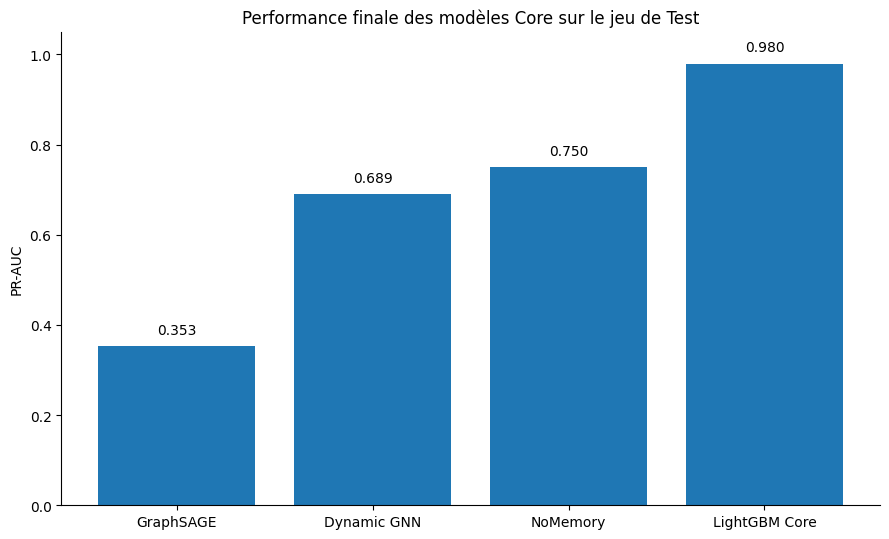

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Résultats finaux
results = pd.DataFrame({
    "Modèle": [
        "GraphSAGE",
        "Dynamic GNN",
        "NoMemory",
        "LightGBM Core"
    ],
    "PR-AUC": [
        0.352779,
        0.689456,
        0.749854,
        0.979749
    ]
})

# Construire la figure
fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    results["Modèle"],
    results["PR-AUC"]
)

ax.set_ylabel("PR-AUC")
ax.set_xlabel("")
ax.set_title("Performance finale des modèles Core sur le jeu de Test")
ax.set_ylim(0, 1.05)

# Ajouter les valeurs
for bar, value in zip(bars, results["PR-AUC"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Comparaison globale des performances

La figure met en évidence une hiérarchie nette entre les quatre modèles Core évalués sur le jeu de Test.

GraphSAGE obtient la PR-AUC la plus faible avec $0.352779$, tandis que l'introduction d'une modélisation temporelle porte la performance du Dynamic GNN à $0.689456$.

Cependant, le contrôle neuronal sans mémoire atteint une PR-AUC supérieure de $0.749854$. Cette observation montre que l'amélioration du Dynamic GNN par rapport à GraphSAGE ne peut pas être attribuée directement à sa mémoire temporelle.

LightGBM Core reste largement supérieur aux approches neuronales étudiées avec une PR-AUC de $0.979749$.

Ces résultats suggèrent que, dans PaySim, les caractéristiques transactionnelles locales contiennent un signal prédictif particulièrement fort, tandis que l'information relationnelle et temporelle exploitée par les architectures GNN étudiées apporte une valeur marginale plus limitée.

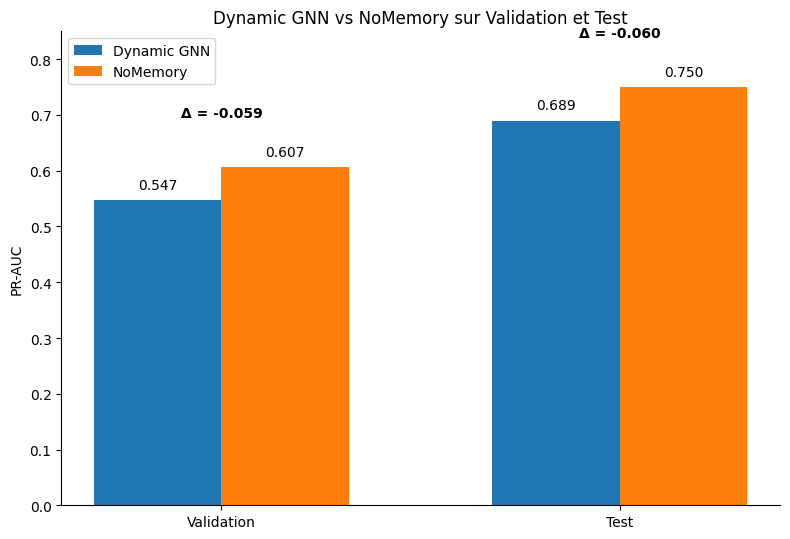

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Résultats de l'ablation
ablation = pd.DataFrame({
    "Split": ["Validation", "Test"],
    "Dynamic GNN": [0.547378, 0.689456],
    "NoMemory": [0.606575, 0.749854]
})

# Position des groupes
x = np.arange(len(ablation["Split"]))
width = 0.32

# Construire la figure
fig, ax = plt.subplots(figsize=(8, 5.5))

bars_dynamic = ax.bar(
    x - width / 2,
    ablation["Dynamic GNN"],
    width,
    label="Dynamic GNN"
)

bars_control = ax.bar(
    x + width / 2,
    ablation["NoMemory"],
    width,
    label="NoMemory"
)

ax.set_ylabel("PR-AUC")
ax.set_title("Dynamic GNN vs NoMemory sur Validation et Test")
ax.set_xticks(x)
ax.set_xticklabels(ablation["Split"])
ax.set_ylim(0, 0.85)
ax.legend()

# Ajouter les valeurs
for bars in [bars_dynamic, bars_control]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

# Ajouter les écarts
deltas = [-0.059197, -0.060397]

for i, delta in enumerate(deltas):
    y = max(
        ablation.loc[i, "Dynamic GNN"],
        ablation.loc[i, "NoMemory"]
    ) + 0.09

    ax.text(
        x[i],
        y,
        f"Δ = {delta:.3f}",
        ha="center",
        fontweight="bold"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Ablation de la mémoire temporelle

La comparaison entre le Dynamic GNN et son contrôle sans mémoire constitue une ablation centrale de l'étude.

Sur l'ensemble de Validation, le Dynamic GNN atteint une PR-AUC de $0.547378$, contre $0.606575$ pour le contrôle NoMemory, soit un écart de :

$$
\Delta_{\text{Validation}} = -0.059197
$$

Sur le jeu de Test, les PR-AUC atteignent respectivement $0.689456$ et $0.749854$, soit :

$$
\Delta_{\text{Test}} = -0.060397
$$

L'amplitude de l'écart est donc presque identique entre Validation et Test.

Cette stabilité est importante : la sous-performance du modèle dynamique n'apparaît pas uniquement sur la période finale de Test, mais est déjà observée sur la Validation utilisée pour la sélection expérimentale.

Ces résultats indiquent que, dans le setting étudié, l'ajout de la mémoire temporelle destination-centric n'apporte pas de gain prédictif au prédicteur neuronal correspondant.

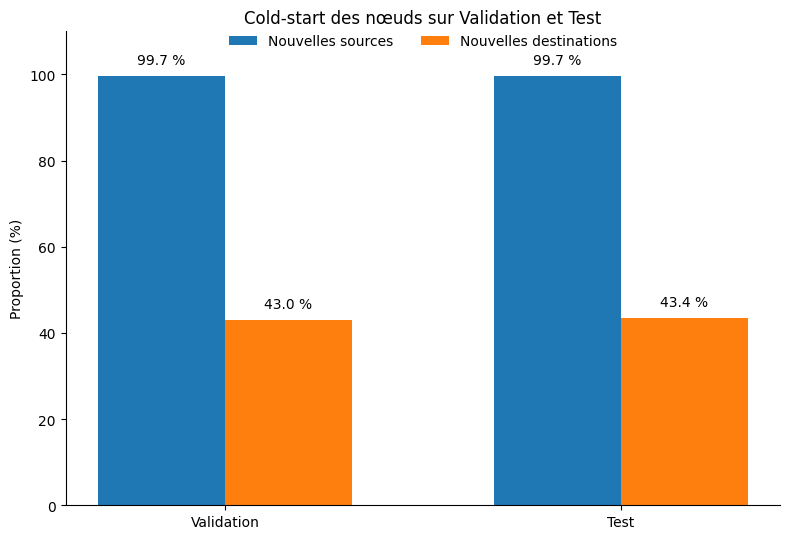

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Taux de cold-start
cold_start = pd.DataFrame({
    "Split": ["Validation", "Test"],
    "Nouvelles sources": [99.7448, 99.7107],
    "Nouvelles destinations": [43.0355, 43.4421]
})

# Position des groupes
x = np.arange(len(cold_start["Split"]))
width = 0.32

# Construire la figure
fig, ax = plt.subplots(figsize=(8, 5.5))

bars_source = ax.bar(
    x - width / 2,
    cold_start["Nouvelles sources"],
    width,
    label="Nouvelles sources"
)

bars_dest = ax.bar(
    x + width / 2,
    cold_start["Nouvelles destinations"],
    width,
    label="Nouvelles destinations"
)

ax.set_ylabel("Proportion (%)")
ax.set_title("Cold-start des nœuds sur Validation et Test")
ax.set_xticks(x)
ax.set_xticklabels(cold_start["Split"])
ax.set_ylim(0, 110)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

# Ajouter les valeurs
for bars in [bars_source, bars_dest]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 2,
            f"{value:.1f} %",
            ha="center",
            va="bottom"
        )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Caractère inductif et cold-start

La structure temporelle du graphe révèle un niveau de cold-start particulièrement élevé.

Sur l'ensemble de Validation, environ $99.74\%$ des sources et $43.04\%$ des destinations sont nouvelles au moment de la prédiction. Des proportions presque identiques sont observées sur Test, avec environ $99.71\%$ de nouvelles sources et $43.44\%$ de nouvelles destinations.

La quasi-totalité des comptes sources ne possède donc aucun historique exploitable lorsqu'une transaction doit être évaluée.

À l'inverse, un peu plus de la moitié des destinations ont déjà été observées, ce qui justifie expérimentalement le choix d'une mémoire temporelle centrée principalement sur les destinations.

Cette asymétrie confirme également le caractère fortement inductif du problème : le modèle doit généralement prendre une décision sur une nouvelle source et ne peut exploiter un historique de nœud que dans une partie des transactions.

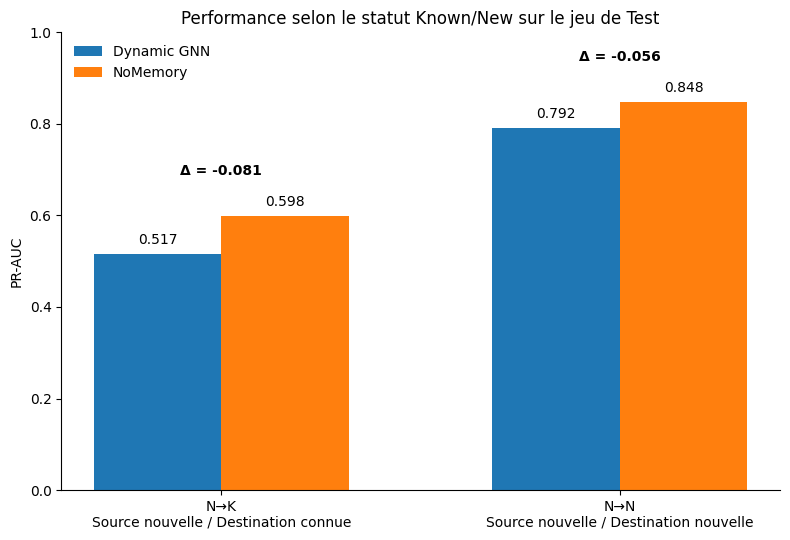

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Résultats Known/New sur Test
known_new = pd.DataFrame({
    "Scénario": ["N→K", "N→N"],
    "Dynamic GNN": [0.516675, 0.791796],
    "NoMemory": [0.597966, 0.847579]
})

# Position des groupes
x = np.arange(len(known_new["Scénario"]))
width = 0.32

# Construire la figure
fig, ax = plt.subplots(figsize=(8, 5.5))

bars_dynamic = ax.bar(
    x - width / 2,
    known_new["Dynamic GNN"],
    width,
    label="Dynamic GNN"
)

bars_control = ax.bar(
    x + width / 2,
    known_new["NoMemory"],
    width,
    label="NoMemory"
)

ax.set_ylabel("PR-AUC")
ax.set_title("Performance selon le statut Known/New sur le jeu de Test")
ax.set_xticks(x)
ax.set_xticklabels([
    "N→K\nSource nouvelle / Destination connue",
    "N→N\nSource nouvelle / Destination nouvelle"
])
ax.set_ylim(0, 1.0)

ax.legend(
    loc="upper left",
    frameon=False
)

# Ajouter les valeurs
for bars in [bars_dynamic, bars_control]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

# Ajouter les écarts
deltas = [-0.081292, -0.055783]

for i, delta in enumerate(deltas):
    y = max(
        known_new.loc[i, "Dynamic GNN"],
        known_new.loc[i, "NoMemory"]
    ) + 0.09

    ax.text(
        x[i],
        y,
        f"Δ = {delta:.3f}",
        ha="center",
        fontweight="bold"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Performance selon le statut Known/New

L'analyse selon le statut des nœuds confirme que l'absence de gain de la mémoire temporelle ne s'explique pas uniquement par le cold-start.

Dans le scénario `N→N`, où la source et la destination sont toutes deux nouvelles, le Dynamic GNN obtient une PR-AUC de $0.791796$, contre $0.847579$ pour le contrôle NoMemory.

Plus important encore, dans le scénario `N→K`, où la source est nouvelle mais où la destination possède déjà un historique, le Dynamic GNN atteint une PR-AUC de $0.516675$, contre $0.597966$ pour NoMemory.

L'écart est donc particulièrement défavorable au modèle dynamique dans le scénario où sa mémoire destination-centric aurait théoriquement dû apporter le plus de valeur.

Ce résultat suggère que la limitation observée ne provient pas uniquement de l'absence d'historique pour les nouveaux nœuds. Dans le setting étudié, l'historique accumulé par les destinations connues ne fournit pas un signal prédictif suffisamment utile pour améliorer le prédicteur sans mémoire.

# 10. Résultats essentiels pour la soutenance

Cette section synthétise les résultats qu'il est important de pouvoir présenter clairement pendant la soutenance.

L'objectif n'est pas de mémoriser l'ensemble des métriques produites au cours du projet, mais de retenir les quelques chiffres permettant de raconter l'histoire scientifique de l'étude.

## 10.1. Un problème fortement déséquilibré

Le dataset PaySim contient :

- $6\,362\,620$ transactions ;
- $8\,213$ transactions frauduleuses ;
- un taux global de fraude d'environ $0.1291\%$.

La fraude constitue donc une classe extrêmement minoritaire.

Cette caractéristique justifie l'utilisation de la **PR-AUC** comme métrique principale de comparaison des modèles.

La ROC-AUC, la précision, le rappel et le score F1 sont conservés comme métriques complémentaires.

## 10.2. Un protocole strictement temporel

Les données ont été séparées selon leur ordre temporel :

| Split | Steps | Transactions | Fraudes |
|---|---|---:|---:|
| Train | 1–334 | 4 771 387 | 3 745 |
| Validation | 335–392 | 792 406 | 638 |
| Test | 393–743 | 798 827 | 3 830 |

Le protocole expérimental respecte les principes suivants :

- aucun random split ;
- aucun shuffle ;
- aucune stratification ;
- aucune information future ;
- aucune sélection de modèle sur Test ;
- aucun seuil sélectionné sur Test ;
- aucun hyperparamètre choisi à partir du Test.

La Validation est utilisée pour les décisions expérimentales.

Le Test est réservé à l'évaluation finale.

Pour le graphe dynamique, la causalité suit :

$$
State_{<t}
\rightarrow
Prediction(E_t)
\rightarrow
Update(E_t)
$$

Les événements du step courant ne sont donc jamais utilisés pour prédire ce même step.

## 10.3. LightGBM Core constitue la référence principale

Sur le jeu de Test, LightGBM Core obtient :

| Métrique | Valeur |
|---|---:|
| PR-AUC | 0.979749 |
| ROC-AUC | 0.999890 |
| Precision | 0.982230 |
| Recall | 0.793730 |
| F1 | 0.877980 |
| TP | 3 040 |
| FP | 55 |
| FN | 790 |

LightGBM Core constitue ainsi la meilleure référence scientifique parmi les modèles Core étudiés.

Il montre qu'une grande partie du signal prédictif de PaySim peut être capturée directement à partir des caractéristiques transactionnelles et historiques causales.

## 10.4. LightGBM Full atteint presque la perfection, mais doit être interprété avec prudence

LightGBM Full atteint sur Test :

$$
PR\text{-}AUC = 0.999740
$$

avec :

$$
Precision = 0.999738
$$

$$
Recall = 0.997389
$$

et :

$$
F1 = 0.998562
$$

Cependant, environ :

$$
99.79\%
$$

du gain d'importance du modèle provient des variables considérées comme **PaySim-sensitive**.

La variable :

`amount_equals_oldbalance`

représente à elle seule environ :

$$
99.66\%
$$

du gain d'importance.

Ces performances presque parfaites doivent donc être interprétées comme une forte exploitation de régularités spécifiques au mécanisme de simulation PaySim.

LightGBM Full reste un résultat expérimental important, mais LightGBM Core est retenu comme référence scientifique principale.

## 10.5. Le graphe PaySim est très pauvre relationnellement

Le graphe transactionnel contient :

- $9\,073\,900$ nœuds ;
- $6\,362\,620$ arêtes.

Malgré sa taille, plusieurs propriétés montrent une faible richesse relationnelle :

- $94.83\%$ des nœuds ont un degré total égal à 1 ;
- $95.78\%$ ont un degré total inférieur ou égal à 2 ;
- les $6\,362\,620$ couples dirigés sont tous uniques ;
- aucune paire source-destination ne se répète ;
- aucune réciprocité ;
- aucun self-loop ;
- aucun cycle.

Seulement :

$$
1\,769
$$

comptes apparaissent à la fois comme source et comme destination, soit environ :

$$
0.0195\%
$$

des nœuds.

Le graphe est donc très grand en nombre de nœuds, mais relativement pauvre en structure relationnelle réutilisable.

## 10.6. GraphSAGE exploite difficilement cette structure

GraphSAGE Core Edge obtient sur Test :

$$
PR\text{-}AUC = 0.352779
$$

avec :

$$
Recall = 0.164752
$$

Le message passing spatial est donc fortement limité dans cette représentation de PaySim.

Cette performance est cohérente avec :

- la faible densité du graphe ;
- les voisinages extrêmement réduits ;
- l'absence de relations répétées ;
- la faible profondeur relationnelle ;
- le très faible chevauchement entre rôles source et destination.

## 10.7. Le Dynamic GNN améliore fortement GraphSAGE

Le Dynamic GNN TBPTT=2 atteint sur Test :

$$
PR\text{-}AUC = 0.689456
$$

contre :

$$
0.352779
$$

pour GraphSAGE.

Le gain est donc :

$$
0.689456 - 0.352779
=
0.336677
$$

L'introduction d'une modélisation temporelle est ainsi nettement plus performante que le message passing spatial statique.

Cependant, cette comparaison ne permet pas encore d'attribuer le gain à la mémoire temporelle.

## 10.8. L'ablation NoMemory constitue le résultat central

Le contrôle neuronal sans mémoire atteint sur Test :

$$
PR\text{-}AUC = 0.749854
$$

contre :

$$
0.689456
$$

pour le Dynamic GNN.

Sur Validation :

$$
\Delta_{\text{Dynamic-Control}}
=
-0.059197
$$

Sur Test :

$$
\Delta_{\text{Dynamic-Control}}
=
-0.060397
$$

L'écart défavorable au modèle dynamique est donc pratiquement identique entre Validation et Test.

Cette stabilité constitue l'un des résultats les plus importants du projet.

Elle montre que la sous-performance de la mémoire temporelle n'est pas uniquement une fluctuation observée sur la période de Test.

## 10.9. Le problème est extrêmement inductif

Le cold-start concerne presque toutes les sources.

Sur Validation :

$$
99.7448\%
$$

des sources sont nouvelles.

Sur Test :

$$
99.7107\%
$$

des sources sont nouvelles.

Pour les destinations :

$$
43.0355\%
$$

sont nouvelles sur Validation et :

$$
43.4421\%
$$

sur Test.

Le modèle dispose donc presque toujours d'une nouvelle source sans historique.

Cette propriété réduit fortement la quantité d'information historique exploitable par un modèle dynamique.

## 10.10. Le scénario N→K constitue un test critique de la mémoire

Sur Test, la catégorie `N→K` correspond à :

- une source nouvelle ;
- une destination déjà connue.

Elle représente donc le scénario où une mémoire destination-centric devrait théoriquement être la plus utile.

Les performances sont :

| Modèle | PR-AUC N→K | TP |
|---|---:|---:|
| Dynamic GNN | 0.516675 | 495 |
| NoMemory | 0.597966 | 608 |

L'écart est :

$$
0.516675 - 0.597966
=
-0.081291
$$

Le Dynamic GNN reste donc inférieur au contrôle sans mémoire précisément dans le scénario où la destination dispose déjà d'un historique.

Ce résultat montre que le cold-start n'explique pas à lui seul les limites observées.

## 10.11. TBPTT=16 permet d'écarter l'hypothèse d'un gradient simplement trop court

Avec TBPTT=2, la proportion de fraudes réellement couverte par le gradient temporel est faible.

La couverture augmente avec l'horizon :

| TBPTT | Couverture des fraudes |
|---:|---:|
| 2 | 4,37 % |
| 4 | 9,39 % |
| 8 | 18,85 % |
| 16 | 29,62 % |
| 32 | 47,31 % |

Une expérience ciblée avec :

$$
TBPTT = 16
$$

a donc été réalisée.

La propagation temporelle du gradient devient effectivement plus importante.

Cependant, la PR-AUC Validation diminue de :

$$
0.547378
$$

pour TBPTT=2 à :

$$
0.395144
$$

pour TBPTT=16.

Ainsi, une meilleure propagation du gradient temporel n'améliore pas automatiquement la qualité prédictive de la mémoire.

## 10.12. Hiérarchie finale des modèles Core

La hiérarchie finale sur Test est :

$$
\boxed{
GraphSAGE
<
Dynamic\ GNN
<
NoMemory
<
LightGBM\ Core
}
$$

avec :

$$
0.352779
<
0.689456
<
0.749854
<
0.979749
$$

en PR-AUC.

Cette ligne constitue la synthèse numérique principale des expérimentations.

## 10.13. Résultats à retenir prioritairement à l'oral

Les principaux chiffres à connaître sont :

| Résultat | Valeur |
|---|---:|
| Taux global de fraude | $\approx 0.1291\%$ |
| LightGBM Core Test PR-AUC | 0.979749 |
| GraphSAGE Test PR-AUC | 0.352779 |
| Dynamic GNN Test PR-AUC | 0.689456 |
| NoMemory Test PR-AUC | 0.749854 |
| Dynamic − NoMemory Validation | -0.059197 |
| Dynamic − NoMemory Test | -0.060397 |
| Nouvelles sources Test | $\approx 99.7\%$ |
| Nouvelles destinations Test | $\approx 43.4\%$ |
| Dynamic − NoMemory sur N→K | $\approx -0.081$ |

## 10.14. Conclusion à défendre pendant la soutenance

La conclusion principale doit être formulée avec précision :

> Dans le setting étudié sur PaySim, la mémoire temporelle destination-centric inspirée de TGN n'apporte pas de gain prédictif par rapport au même prédicteur neuronal sans mémoire.

Ce résultat peut être mis en relation avec :

- la forte sparsité du graphe ;
- la faible récurrence relationnelle ;
- le cold-start massif des sources ;
- la faible profondeur topologique ;
- le faible chevauchement entre sources et destinations ;
- la force du signal transactionnel local.

Cette conclusion ne doit pas être généralisée à l'ensemble des GNN dynamiques ou à l'ensemble des données de fraude financière.

# 11. Executive Summary scientifique du PFE

## 11.1. Objectif de l'étude

Ce Projet de Fin d'Études étudie l'intérêt du **Graph Learning dynamique pour la détection de fraude Mobile Money**, à travers une comparaison entre modèles tabulaires, Graph Neural Networks statiques et architecture temporelle à mémoire.

Les expérimentations sont réalisées sur le dataset simulé **PaySim**.

L'objectif n'est pas uniquement d'identifier le modèle obtenant le meilleur score, mais également de déterminer si la structure relationnelle et l'historique temporel des transactions apportent une information prédictive supplémentaire par rapport aux caractéristiques transactionnelles classiques.

## 11.2. Dataset et protocole expérimental

PaySim contient :

- $6\,362\,620$ transactions ;
- $8\,213$ fraudes ;
- un taux global de fraude d'environ $0.1291\%$ ;
- $743$ steps temporels.

Les données sont séparées chronologiquement :

| Split | Steps | Transactions | Fraudes |
|---|---|---:|---:|
| Train | 1–334 | 4 771 387 | 3 745 |
| Validation | 335–392 | 792 406 | 638 |
| Test | 393–743 | 798 827 | 3 830 |

Le protocole repose sur une séparation temporelle stricte :

- aucun random split ;
- aucun shuffle ;
- aucune stratification ;
- aucune fuite temporelle ;
- aucune sélection de modèle sur Test ;
- aucun seuil sélectionné sur Test ;
- aucun hyperparamètre choisi à partir du Test.

Pour les modèles dynamiques, la prédiction respecte :

$$
State_{<t}
\rightarrow
Prediction(E_t)
\rightarrow
Update(E_t)
$$

Les événements observés au step $t$ ne sont donc jamais utilisés pour prédire d'autres événements appartenant au même step.

## 11.3. Baseline Machine Learning

La référence tabulaire principale, **LightGBM Core**, obtient sur Test :

$$
PR\text{-}AUC = 0.979749
$$

avec :

$$
Precision = 0.982230
$$

$$
Recall = 0.793730
$$

et :

$$
F1 = 0.877980
$$

Une variante plus riche, **LightGBM Full**, atteint :

$$
PR\text{-}AUC = 0.999740
$$

Cependant, environ :

$$
99.79\%
$$

du gain d'importance de cette variante provient de variables fortement sensibles au mécanisme de simulation de PaySim.

La variable :

`amount_equals_oldbalance`

représente à elle seule environ :

$$
99.66\%
$$

du gain.

Pour cette raison, LightGBM Core est retenu comme référence scientifique principale, tandis que LightGBM Full est conservé comme résultat complémentaire montrant la présence de régularités extrêmement fortes dans le simulateur.

## 11.4. Structure du graphe PaySim

Le graphe transactionnel contient :

$$
9\,073\,900
$$

nœuds et :

$$
6\,362\,620
$$

arêtes.

Cependant, sa structure est extrêmement sparse.

Environ :

$$
94.83\%
$$

des nœuds ont un degré total égal à 1 et :

$$
95.78\%
$$

ont un degré inférieur ou égal à 2.

Chaque paire dirigée source-destination n'apparaît qu'une seule fois.

Le graphe ne contient :

- aucune réciprocité ;
- aucun self-loop ;
- aucun cycle.

Seulement :

$$
1\,769
$$

comptes jouent à la fois le rôle de source et de destination, soit environ :

$$
0.0195\%
$$

des nœuds.

Le graphe est donc très grand mais relativement pauvre en structure relationnelle récurrente.

## 11.5. GraphSAGE

La baseline GNN statique **GraphSAGE Core Edge** atteint sur Test :

$$
PR\text{-}AUC = 0.352779
$$

avec :

$$
Recall = 0.164752
$$

Ces performances modestes sont cohérentes avec la très faible richesse topologique du graphe.

Le message passing spatial dispose de peu de voisinages récurrents, de chemins multi-hops ou de motifs structurels permettant d'enrichir efficacement les représentations des transactions.

## 11.6. Dynamic GNN

Une architecture dynamique légère inspirée du principe de mémoire de TGN a été développée.

Elle combine :

- les variables `Graph Core Edge` ;
- une mémoire temporelle sparse centrée sur les destinations ;
- un module de message ;
- une agrégation moyenne intra-step ;
- une GRU ;
- un prédicteur d'arêtes.

Aucun embedding de `node_id` n'est utilisé.

Les labels historiques ne sont pas intégrés dans la mémoire.

Les nouveaux nœuds utilisent un état initial partagé.

Le Dynamic GNN TBPTT=2 atteint sur Test :

$$
PR\text{-}AUC = 0.689456
$$

Il améliore donc fortement GraphSAGE :

$$
0.689456 - 0.352779
=
0.336677
$$

de PR-AUC.

Cependant, cette amélioration ne suffit pas à démontrer l'utilité de la mémoire temporelle.

## 11.7. Ablation NoMemory

Afin d'isoler la contribution de la mémoire, un contrôle neuronal sans mémoire a été entraîné.

Ce modèle retire :

- la mémoire historique ;
- le message module ;
- la GRU ;
- les informations Known/New ;
- le $\Delta t$.

Il atteint sur Test :

$$
PR\text{-}AUC = 0.749854
$$

soit une performance supérieure au Dynamic GNN.

Sur Validation :

$$
\Delta_{\text{Dynamic-Control}}
=
-0.059197
$$

Sur Test :

$$
\Delta_{\text{Dynamic-Control}}
=
-0.060397
$$

La stabilité de cet écart entre Validation et Test constitue l'un des principaux résultats scientifiques de l'étude.

Elle indique que la mémoire temporelle destination-centric n'améliore pas le prédicteur neuronal correspondant dans le setting étudié.

## 11.8. Cold-start et analyse Known/New

Le problème est fortement inductif.

Sur Test :

$$
99.7107\%
$$

des sources sont nouvelles et :

$$
43.4421\%
$$

des destinations sont nouvelles.

Le scénario `N→K`, dans lequel la source est nouvelle mais la destination est déjà connue, est particulièrement important car il correspond au cas où la mémoire destination-centric devrait théoriquement être la plus utile.

Sur cette catégorie :

$$
PR\text{-}AUC_{Dynamic}
=
0.516675
$$

contre :

$$
PR\text{-}AUC_{NoMemory}
=
0.597966
$$

soit :

$$
\Delta
\approx
-0.081
$$

en défaveur du Dynamic GNN.

La limitation de la mémoire ne s'explique donc pas uniquement par l'absence d'historique pour les nouveaux nœuds.

Même lorsqu'un historique de destination est disponible, il ne produit pas de gain prédictif dans l'architecture étudiée.

## 11.9. Diagnostic TBPTT

Une hypothèse possible était que :

$$
TBPTT = 2
$$

soit insuffisant pour apprendre correctement les dépendances temporelles.

Une expérience ciblée avec :

$$
TBPTT = 16
$$

a donc été menée.

L'augmentation de l'horizon améliore effectivement la propagation temporelle des gradients.

Cependant, la PR-AUC Validation diminue de :

$$
0.547378
$$

pour TBPTT=2 à :

$$
0.395144
$$

pour TBPTT=16.

Une meilleure propagation du gradient temporel n'améliore donc pas automatiquement la qualité prédictive de la mémoire.

La variante TBPTT=16 a été rejetée sur Validation et n'a pas été évaluée sur Test.

## 11.10. Hiérarchie finale des modèles

La hiérarchie finale des modèles Core sur Test est :

$$
\boxed{
\text{GraphSAGE}
<
\text{Dynamic GNN}
<
\text{NoMemory}
<
\text{LightGBM Core}
}
$$

avec :

$$
0.352779
<
0.689456
<
0.749854
<
0.979749
$$

en PR-AUC.

Cette hiérarchie montre que le signal transactionnel local est beaucoup plus discriminant dans PaySim que le signal relationnel et temporel supplémentaire extrait par les modèles de Graph Learning étudiés.

## 11.11. Interprétation scientifique

Les résultats suggèrent que la valeur limitée du Graph Learning dans cette étude s'explique par la combinaison de plusieurs propriétés :

- graphe extrêmement sparse ;
- absence de répétition des couples transactionnels ;
- faible profondeur relationnelle ;
- quasi-absence de comptes jouant les deux rôles ;
- cold-start massif des sources ;
- forte proportion de destinations nouvelles ;
- signal transactionnel local particulièrement discriminant.

Le graphe contient donc relativement peu d'information relationnelle supplémentaire à exploiter une fois les caractéristiques locales de la transaction connues.

La performance élevée de LightGBM Core est cohérente avec cette structure.

## 11.12. Conclusion scientifique

La conclusion du projet ne doit pas être :

> Les GNN dynamiques ne fonctionnent pas pour la détection de fraude.

La conclusion soutenue par les expériences est plus précise :

> **Dans le setting étudié sur PaySim, la mémoire temporelle destination-centric inspirée de TGN n'apporte pas de gain prédictif par rapport au même prédicteur neuronal sans mémoire.**

Cette conclusion est spécifique :

- au dataset PaySim ;
- à la représentation transactionnelle utilisée ;
- aux ensembles de variables étudiés ;
- au protocole temporel causal ;
- à GraphSAGE ;
- à l'architecture dynamique légère développée.

Elle ne peut pas être généralisée automatiquement à :

- TGN ;
- TGAT ;
- DyRep ;
- l'ensemble des Dynamic GNN ;
- l'ensemble des datasets de fraude ;
- de véritables réseaux Mobile Money.

## 11.13. Limites et perspectives principales

La principale limite concerne l'utilisation de PaySim, qui reste un dataset simulé possédant une structure relationnelle très différente de celle que pourrait présenter un véritable réseau Mobile Money.

Une validation future devrait porter sur des données réelles présentant davantage :

- de comptes récurrents ;
- de communautés ;
- de cycles ;
- de chaînes de transferts ;
- de comptes relais ;
- de relations multi-hops ;
- de comportements coordonnés.

Une autre perspective consiste à construire des graphes hétérogènes intégrant plusieurs types d'entités :

- clients ;
- comptes ;
- agents ;
- marchands ;
- terminaux ;
- appareils ;
- localisations.

Dans ce type de contexte, l'information relationnelle pourrait devenir beaucoup plus importante que dans PaySim.

## 11.14. Message final du projet

Le principal enseignement du PFE peut être résumé ainsi :

> **Un problème peut être naturellement représentable sous forme de graphe sans que le graphe constitue nécessairement sa principale source d'information prédictive. La valeur du Graph Learning dépend avant tout de la richesse relationnelle réellement présente dans les données.**

Le projet montre ainsi l'importance de combiner :

- des baselines tabulaires fortes ;
- une évaluation temporelle rigoureuse ;
- une analyse structurelle du graphe ;
- des expériences d'ablation ;
- une interprétation prudente des performances.

Cette démarche permet de distinguer la complexité d'un modèle de sa véritable valeur ajoutée scientifique.